# Oscillator Kerr from detuned JC coupling

$$
\boxed{\frac{H_K}{h}=\frac{k}{2}n(n-1),\qquad k\equiv K/2\pi\ \text{in kHz}}
$$

250 ns complete swap → $g/2\pi=1$ MHz. Transmon $\alpha/2\pi=-150$ MHz.
Fidelity inputs: **n=0…8; cavity dimension 10; transmon dimension 5**. No decoherence.

[Paper, Appendix B](https://arxiv.org/pdf/2611.05460) ·
[Existing Hamiltonian/helpers](../Optimal%20control/helpful_functions.py).

**Requirement:** the input qubit may be any unknown superposition of g/e and must be preserved. Ground-only curves are comparisons, not qualifying gates.

**Detuning reference:** all sweep axes use the g/e exchange detuning, not the e/f detuning:

$$
\delta_{ge}=\Delta,\qquad \delta_{ef}=\Delta-K,\qquad K=-\alpha>0.
$$

Thus $\Delta/(2\pi)=140\,\mathrm{MHz}$ means $\delta_{ef}/(2\pi)=-10\,\mathrm{MHz}$.


## Echo → unconditional Kerr

$$
\begin{aligned}
\frac{H}{\hbar}&=\omega_an+\frac{K_g}{2}n(n-1)\\
&\quad+\left[\chi_en+\frac{\chi'_e}{2}n(n-1)\right]P_e,\\
\overline{P_e}&=\frac{P_e+P_g}{2}=\frac I2.
\end{aligned}
$$

$$
\boxed{k_{\mathrm{echo}}=k_g+\frac{\chi'_e}{4\pi}}
$$

For $K=-\alpha>0$, the fourth-order result is

$$
K_{\mathrm{echo}}^{(4)}=-\frac{4\Delta K g^4}{(\Delta-K)^3(2\Delta-3K)(2\Delta-K)}.
$$

Near the two-level limit, $K_g^{(4)}=2g^4/\Delta^3$ cancels
$\chi_e'^{(4)}/2=-2g^4/\Delta^3$. The leading residual is
$K_{\mathrm{echo}}\simeq6g^6/\Delta^5$. Virtual higher transmon levels remain in the model.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import qutip as qt
from scipy.linalg import eigh, eigh_tridiagonal
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.special import factorial
from IPython.display import display, Markdown

# Work from the notebook directory, repository root, or the boson workspace.
repo_root = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / 'quantum-simulation-code']:
        if (candidate / 'Optimal control' / 'helpful_functions.py').is_file():
            repo_root = candidate
            break
    if repo_root is not None:
        break
assert repo_root is not None, 'Cannot find Optimal control/helpful_functions.py'
sys.path.insert(0, str(repo_root / 'Optimal control'))
from helpful_functions import dchi_H, K_osc, chi_e, chi_e_prime

output_dir = repo_root / 'Quantum control' / 'results' / 'oscillator_kerr_from_detuned_JC'
output_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print('Helpers:', repo_root / 'Optimal control' / 'helpful_functions.py')

Helpers: /home/tunmays_rsl_pc_wsl/boson/quantum-simulation-code/Optimal control/helpful_functions.py


In [2]:
# All physical inputs and numerical controls are here. MHz means cycles/us.
swap_time_ns = 250.0                  # |e,0> -> |g,1>, a complete excitation swap
alpha_mhz = -150.0                   # negative transmon anharmonicity
g_mhz = 1.0 / (4.0 * swap_time_ns * 1e-3)
K_mhz = -alpha_mhz                   # the paper uses positive K
n_max = 8                           # user-requested Kerr fidelity subspace n=0..8
cavity_levels = 10                   # user-requested dimension: n=0..9
qubit_levels = 5                     # user-requested dimension: g,e,f,h,i
table_detunings_mhz = np.array([5., 10., 20., 50., 70., 80., 100.,
                                130., 140., 145., 155., 160., 170., 220., 230.])
detuning_grid_mhz = np.linspace(-50., 247.5, 1191)
pole_exclusion_mhz = 0.75            # display gap, not a validity guarantee

# Full time-domain example; keep finite ramps in both the time and phase budget.
pulse_detuning_mhz = 140.0
ramp_time_us = 0.5
flat_time_us = 12.003                # EACH flat top; noninteger bare-qubit phase at endpoints
coarse_ramp_step_us = 0.002
fine_ramp_step_us = 0.001
flat_trace_samples = 6003            # about 2 ns sampling; exact constant-H propagation
coherent_alpha = np.sqrt(2.0)
input_qubit = np.array([1., 1.]) / np.sqrt(2)   # |+>, to test qubit disentangling

# Full-H parameter studies; every row uses the same Fock subspace and cutoffs.
ramp_study_detunings_mhz = [5., 10., 20., 140.]
ramp_study_times_us = [0.025, 0.05, 0.1, 0.2, 0.5, 1., 2., 4.]
resonance_centers_mhz = [K_mhz/2, K_mhz, 3*K_mhz/2]
resonance_offsets_mhz = [-5., -1., -0.2, -0.05, 0., 0.05, 0.2, 1., 5.]
resonance_ramp_times_us = [0.1, 0.5, 2.]
long_resonance_ramp_times_us = [5., 10.]

assert alpha_mhz < 0 and n_max >= 2 and cavity_levels >= n_max+2 and qubit_levels >= 4
assert swap_time_ns > 0 and ramp_time_us > 0 and flat_time_us >= 0
print(f'g/2pi = {g_mhz:.6f} MHz; alpha/2pi = {alpha_mhz:.3f} MHz')
print(f'Fock states n=0..{n_max}; {qubit_levels} transmon levels')
print(f'Two lobes: total time = {2 * (2*ramp_time_us + flat_time_us):.3f} us')

g/2pi = 1.000000 MHz; alpha/2pi = -150.000 MHz
Fock states n=0..8; 5 transmon levels
Two lobes: total time = 26.006 us


## Played sequence

```text
input ── [Hann ↑ | flat | Hann ↓] ── πx ── [Hann ↑ | flat | Hann ↓] ── πx ── output
g(t)          0 → g → 0             0          0 → g → 0             0
time       0─────────────────────── L ────────────────────────────── 2L
```

Fock inputs: $|n,g\rangle$, $|n,e\rangle$, n=0…8. Time trace: $|\sqrt2\rangle|+\rangle$.
Preparation is state initialization. Each π is instantaneous $R_x(\pi)$ on g/e,
identity on higher levels, with coupling off. Endpoint $R(2L)$ below is a frame change.

pi at 13.003000 us: detuned-frame phase = -2.638938 rad; final-frame phase = 0
pi at 26.006000 us: detuned-frame phase = +1.005310 rad; final-frame phase = 0
TITLED: sequence_diagram.png: 2 panels


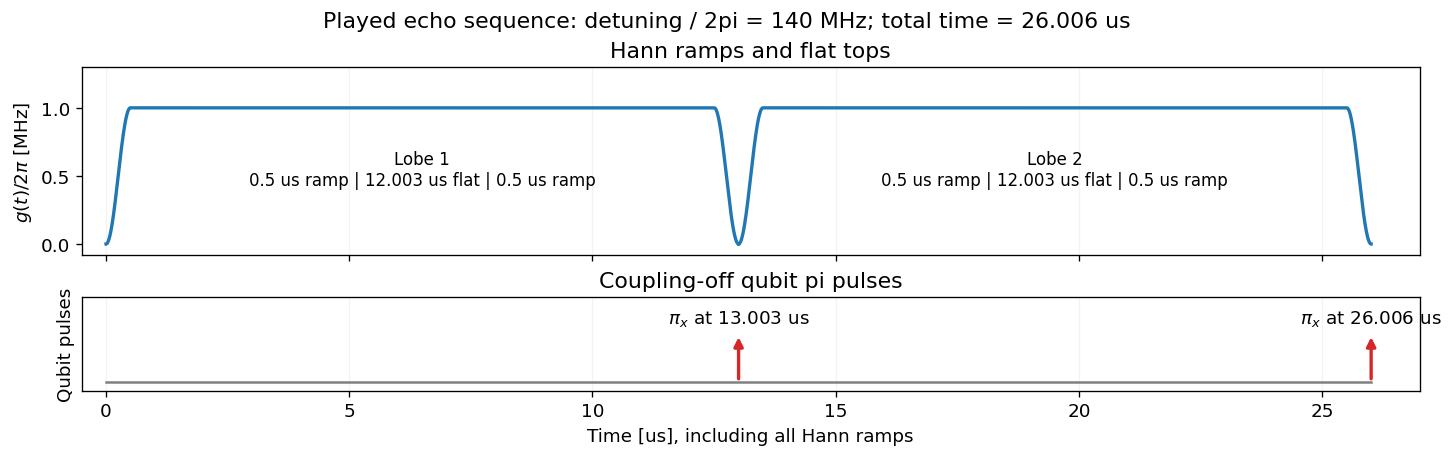

In [3]:
# Draw the actual waveform and pulse times from the input cell.
L = 2*ramp_time_us+flat_time_us
fig, axes = plt.subplots(2, 1, figsize=(12, 3.7), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]}, constrained_layout=True)
for lobe_index in range(2):
    start = lobe_index*L
    up_t = np.linspace(0, ramp_time_us, 101)
    down_t = np.linspace(0, ramp_time_us, 101)
    t = np.r_[up_t, ramp_time_us+flat_time_us, ramp_time_us+flat_time_us+down_t]
    amplitude = np.r_[g_mhz*(1-np.cos(np.pi*up_t/ramp_time_us))/2,
                      g_mhz, g_mhz*(1+np.cos(np.pi*down_t/ramp_time_us))/2]
    axes[0].plot(start+t, amplitude, color='tab:blue', lw=2)
    axes[0].text(start+L/2, 0.55*g_mhz,
                 f'Lobe {lobe_index+1}\n{ramp_time_us:g} us ramp | {flat_time_us:g} us flat | {ramp_time_us:g} us ramp',
                 ha='center', va='center', fontsize=10)
axes[0].set_ylabel(r'$g(t)/2\pi$ [MHz]')
axes[0].set_ylim(-0.08*g_mhz, 1.3*g_mhz)
axes[0].set_title(f'Detuning / 2pi = {pulse_detuning_mhz:g} MHz; total time = {2*L:.3f} us')
axes[1].plot([0, 2*L], [0, 0], color='gray')
for time in [L, 2*L]:
    phase = np.angle(np.exp(-2j*np.pi*pulse_detuning_mhz*time))
    axes[1].annotate('', xy=(time, 0.85), xytext=(time, 0),
                     arrowprops={'arrowstyle': '-|>', 'color': 'tab:red', 'lw': 2})
    axes[1].text(time, 0.95, rf'$\pi_x$ at {time:.3f} us', ha='center', va='bottom')
    print(f'pi at {time:.6f} us: detuned-frame phase = {phase:+.6f} rad; final-frame phase = 0')
axes[1].set_ylim(-0.15, 1.5)
axes[1].set_yticks([])
axes[1].set_ylabel('Qubit pulses')
axes[1].set_xlabel('Time [us], including all Hann ramps')
axes[1].set_xlim(-0.5, 2*L+1)
for ax in axes:
    ax.grid(axis='x', alpha=0.15)
axes[0].set_title('Hann ramps and flat tops')
axes[1].set_title('Coupling-off qubit pi pulses')
fig.suptitle(f'Played echo sequence: detuning / 2pi = {pulse_detuning_mhz:g} MHz; total time = {2*L:.3f} us')
fig.savefig(output_dir / 'sequence_diagram.png', dpi=200)
plt.show()

## Existing-helper conventions

$$
K=-\alpha>0,\qquad \chi'_{e,\mathrm{paper}}=2\,\chi'_{e,\mathrm{helper}}.
$$

The existing `chi_e_prime` helper has half the coefficient in Eq. B13g.
The conversion is explicit below; the shared file is unchanged. MHz inputs give MHz outputs.

In [4]:
def analytic_rates(detuning_mhz):
    """Paper convention: H/h has K_g*n*(n-1)/2 and chi_prime*n*(n-1)*P_e/2."""
    delta = np.asarray(detuning_mhz, dtype=float)
    ground_kerr = K_osc(g_mhz, K_mhz, delta)
    chi_prime_paper = 2.0 * chi_e_prime(g_mhz, K_mhz, delta)
    # Simplified sum avoids losing precision when two large terms cancel.
    echo_kerr = (-4 * delta * K_mhz * g_mhz**4 /
                 ((delta-K_mhz)**3 * (2*delta-3*K_mhz) * (2*delta-K_mhz)))
    return ground_kerr, chi_prime_paper, echo_kerr


def dressed_ladders(detuning_mhz, coupling_mhz=g_mhz, max_photon=n_max,
                    levels=qubit_levels):
    """Diagonalize fixed-total-excitation blocks; label by connection to g=0.

    This replaces rounding <n_q> and <n_a>, which can duplicate or lose labels
    near hybridization. No eigenstate or photon interval is silently skipped.
    For nondegenerate bare energies, eigenvalue rank tracks the g=0 branch.
    The production model has the user's five-level transmon truncation.
    Exact bare resonances are excluded: the adiabatic label there is ambiguous.
    """
    energies = np.full((max_photon+1, 2), np.nan)
    overlaps = np.full_like(energies, np.nan)
    for total in range(max_photon+2):
        q_numbers = np.arange(min(total+1, levels))
        bare = detuning_mhz*q_numbers + alpha_mhz*q_numbers*(q_numbers-1)/2
        hopping = coupling_mhz*np.sqrt((total-q_numbers[:-1])*(q_numbers[:-1]+1))
        if len(bare) == 1:
            values, vectors = bare.copy(), np.ones((1, 1))
        else:
            values, vectors = eigh_tridiagonal(bare, hopping, lapack_driver='stev')
        for q_input in [0, 1]:
            photon = total-q_input
            if photon < 0 or photon > max_photon or q_input >= len(bare):
                continue  # these labels are outside the requested rectangular g/e grid
            assert np.count_nonzero(np.isclose(bare, bare[q_input], atol=1e-10, rtol=0)) == 1, (
                f'Bare resonance at delta={detuning_mhz}; choose a nonresonant detuning')
            rank = np.count_nonzero(bare < bare[q_input])
            energies[photon, q_input] = values[rank]
            overlaps[photon, q_input] = abs(vectors[q_input, rank])**2
    assert energies.size == 2*(max_photon+1) and np.all(np.isfinite(energies))
    assert np.all(np.isfinite(overlaps))
    return energies, overlaps


def ladder_rates(energies):
    """Second finite differences are constant in photon number for a pure Kerr."""
    ground = np.diff(energies[:, 0], n=2)
    excited = np.diff(energies[:, 1], n=2)
    echo = (ground + excited)/2
    chi_prime = excited-ground
    return ground, chi_prime, echo

In [5]:
# The analytic poles occur at multiples of K/2. Exact branches also hybridize there.
poles_mhz = K_mhz * np.arange(0, 5) / 2
distance_to_pole = np.min(abs(detuning_grid_mhz[:, None]-poles_mhz[None, :]), axis=1)
detunings_mhz = detuning_grid_mhz[distance_to_pole > pole_exclusion_mhz]
spectra = np.empty((len(detunings_mhz), n_max+1, 2))
bare_overlaps = np.empty_like(spectra)
for index, delta in enumerate(detunings_mhz):
    spectra[index], bare_overlaps[index] = dressed_ladders(delta)
    if (index+1) % 200 == 0:
        print(f'Spectra running: {index+1}/{len(detunings_mhz)} detunings', flush=True)

ground_exact = np.diff(spectra[:, :, 0], n=2, axis=1)
excited_exact = np.diff(spectra[:, :, 1], n=2, axis=1)
echo_exact = (ground_exact+excited_exact)/2
chi_prime_exact = excited_exact-ground_exact
ground_fourth, chi_prime_fourth, echo_fourth = analytic_rates(detunings_mhz)
assert spectra.size == len(detunings_mhz)*2*(n_max+1)
assert ground_exact.size == len(detunings_mhz)*(n_max-1)
print(f'MEASURED: {len(detunings_mhz)} detunings, {spectra.size} dressed energies, '
      f'{ground_exact.size} photon intervals for EACH Kerr curve.', flush=True)

Spectra running: 200/1163 detunings


Spectra running: 400/1163 detunings


Spectra running: 600/1163 detunings


Spectra running: 800/1163 detunings


Spectra running: 1000/1163 detunings


MEASURED: 1163 detunings, 20934 dressed energies, 8141 photon intervals for EACH Kerr curve.


TITLED: paper_comparison_and_echo.png: 3 panels


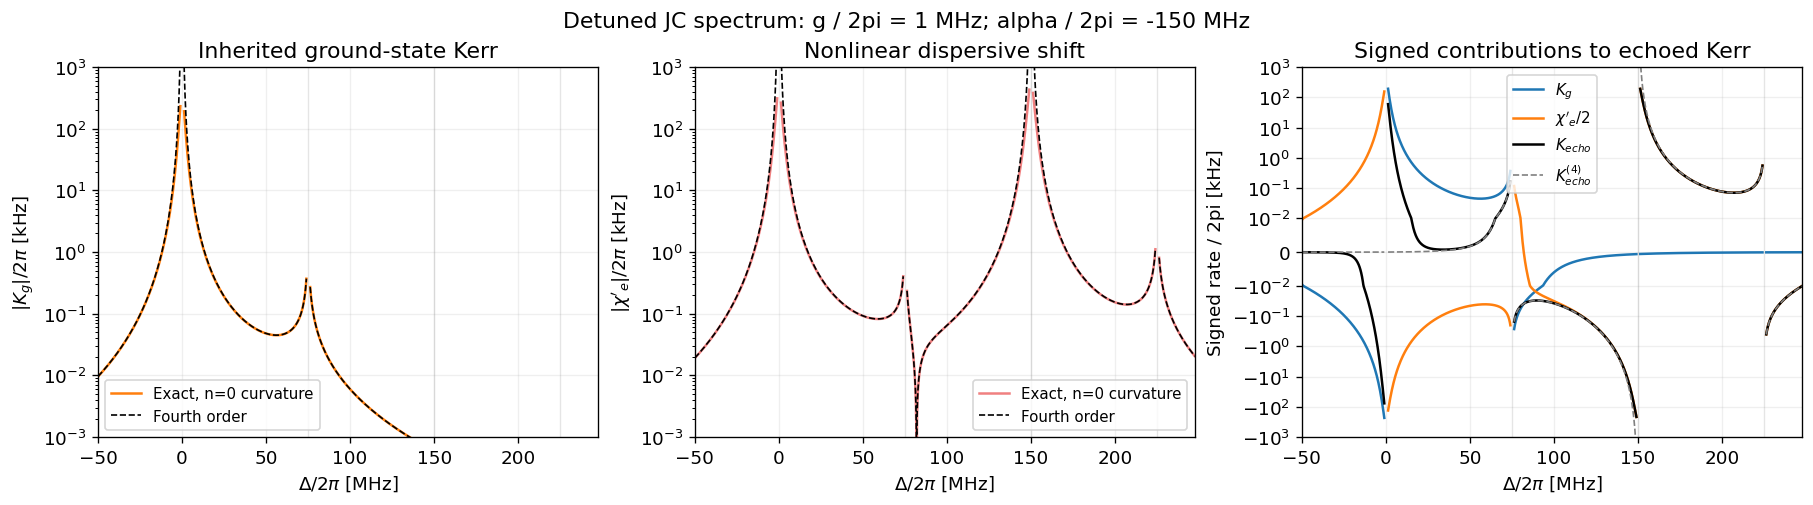

In [6]:
# Reproduce the paper's magnitude plots, and expose the signed echo sum separately.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.1), constrained_layout=True)
# NaN x coordinates break connecting lines across excluded resonance windows.
plot_detunings_mhz = detunings_mhz.copy()
plot_detunings_mhz[np.r_[False, np.diff(detunings_mhz) > 0.375]] = np.nan
for ax, exact, analytic, name, color in [
    (axes[0], ground_exact[:, 0], ground_fourth, r'$|K_g|/2\pi$', 'tab:orange'),
    (axes[1], chi_prime_exact[:, 0], chi_prime_fourth, r"$|\chi'_e|/2\pi$", 'lightcoral')]:
    ax.semilogy(plot_detunings_mhz, abs(exact)*1e3, color=color, label='Exact, n=0 curvature')
    ax.semilogy(plot_detunings_mhz, abs(analytic)*1e3, 'k--', lw=1, label='Fourth order')
    ax.set_ylabel(name + ' [kHz]')
    ax.set_ylim(1e-3, 1e3)
    ax.legend(fontsize=9)
axes[2].plot(plot_detunings_mhz, ground_exact[:, 0]*1e3, label=r'$K_g$')
axes[2].plot(plot_detunings_mhz, chi_prime_exact[:, 0]*0.5e3, label=r"$\chi'_e/2$")
axes[2].plot(plot_detunings_mhz, echo_exact[:, 0]*1e3, label=r'$K_{echo}$', color='black')
axes[2].plot(plot_detunings_mhz, echo_fourth*1e3, '--', color='gray', lw=1,
             label=r'$K_{echo}^{(4)}$')
axes[2].set_yscale('symlog', linthresh=0.01)
axes[2].set_ylim(-1e3, 1e3)
axes[2].set_ylabel('Signed rate / 2pi [kHz]')
axes[2].legend(fontsize=9)
for ax in axes:
    ax.set_xlabel(r'$\Delta/2\pi$ [MHz]')
    for pole in poles_mhz[1:]:
        ax.axvline(pole, color='gray', alpha=0.2, lw=0.8)
    ax.grid(alpha=0.2)
    ax.set_xlim(-50, 247.5)
axes[0].set_title('Inherited ground-state Kerr')
axes[1].set_title('Nonlinear dispersive shift')
axes[2].set_title('Signed contributions to echoed Kerr')
fig.suptitle(f'Detuned JC spectrum: g / 2pi = {g_mhz:g} MHz; alpha / 2pi = {alpha_mhz:g} MHz')
fig.savefig(output_dir / 'paper_comparison_and_echo.png', dpi=200)
plt.show()

TITLED: photon_number_dependence.png: 2 panels


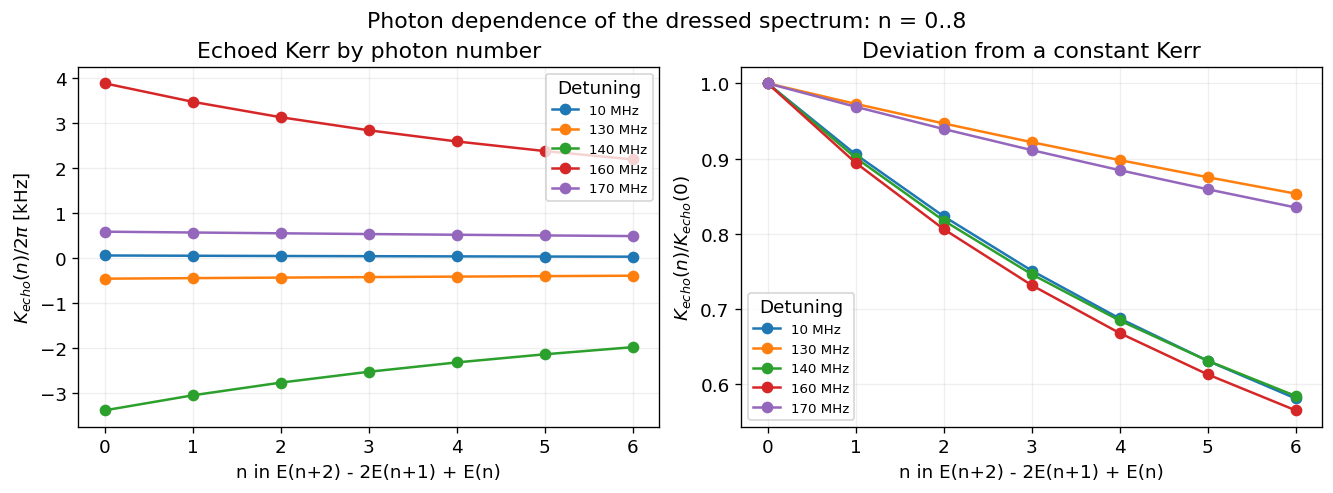

In [7]:
rows = []
table_spectra = {}
for delta in table_detunings_mhz:
    energies, overlaps = dressed_ladders(delta)
    kg, chip, ke = ladder_rates(energies)
    table_spectra[delta] = energies
    rows.append({'delta_MHz': delta, 'Kg_kHz': 1e3*kg[0],
                 'chi_prime_kHz': 1e3*chip[0], 'Kecho_kHz': 1e3*ke[0],
                 'Kecho_min_over_n_kHz': 1e3*ke.min(),
                 'Kecho_max_over_n_kHz': 1e3*ke.max(),
                 'min_bare_overlap': overlaps.min(),
                 'echo_pi_phase_on_n2_us': 0.5/abs(ke[0])})
rate_table = pd.DataFrame(rows)
rate_table.to_csv(output_dir / 'exact_rate_table.csv', index=False)
pd.DataFrame({'delta_MHz': detunings_mhz,
              'Kg_exact_kHz': 1e3*ground_exact[:, 0],
              'chi_prime_exact_kHz': 1e3*chi_prime_exact[:, 0],
              'Kecho_exact_kHz': 1e3*echo_exact[:, 0],
              'Kg_fourth_kHz': 1e3*ground_fourth,
              'chi_prime_fourth_kHz': 1e3*chi_prime_fourth,
              'Kecho_fourth_kHz': 1e3*echo_fourth,
              'min_bare_overlap': bare_overlaps.min(axis=(1, 2))}).to_csv(
                  output_dir / 'detuning_sweep.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for delta in [10., 130., 140., 160., 170.]:
    kg, chip, ke = ladder_rates(table_spectra[delta])
    axes[0].plot(np.arange(n_max-1), ke*1e3, 'o-', label=f'{delta:g} MHz')
    axes[1].plot(np.arange(n_max-1), ke/ke[0], 'o-', label=f'{delta:g} MHz')
axes[0].set_ylabel(r'$K_{echo}(n)/2\pi$ [kHz]')
axes[1].set_ylabel(r'$K_{echo}(n)/K_{echo}(0)$')
for ax in axes:
    ax.set_xlabel('n in E(n+2) - 2E(n+1) + E(n)')
    ax.grid(alpha=0.2)
    ax.legend(title='Detuning', fontsize=8)
axes[0].set_title('Echoed Kerr by photon number')
axes[1].set_title('Deviation from a constant Kerr')
fig.suptitle(f'Photon dependence of the dressed spectrum: n = 0..{n_max}')
fig.savefig(output_dir / 'photon_number_dependence.png', dpi=200)
plt.show()

## Full time-domain Hamiltonian and frames

Use $\delta=\Delta/2\pi$, $\alpha_f=\alpha/2\pi$, and $n_q=q^\dagger q$ with **bare** q:

$$
\frac{H_D(t)}h=\delta n_q+\frac{\alpha_f}{2}n_q(n_q-1)+g_f(t)(a^\dagger q+aq^\dagger).
$$

Each edge is a half Hann; the middle is flat:

$$
g_\uparrow(t)=\frac{g_f}{2}[1-\cos(\pi t/t_r)],\qquad
g_\downarrow(t)=\frac{g_f}{2}[1+\cos(\pi t/t_r)].
$$

```text
both modes at cavity frequency  ── R(t) = exp(+i 2π δ nq t) ── cavity + bare-qubit frame
            U_D(t)                                           U_I(t) = R(t) U_D(t)
```

$$
\frac{H_I(t)}h=\frac{\alpha_f}{2}n_q(n_q-1)+g_f(t)
\big(e^{-i2\pi\delta t}a^\dagger q+e^{+i2\pi\delta t}aq^\dagger\big).
$$

Include ramp time in T. Transform pulse axes too:

$$
X_D(t_p)=R^\dagger(t_p)X_\pi R(t_p),\qquad
U_{I,\mathrm{echo}}(2L)=R(2L)X_D(2L)F X_D(L)F.
$$

F propagates one full Hann–flat–Hann lobe. Full-H dynamics include exchange and leakage;
instantaneous dressed energies supply only the comparison curve.

In [8]:
def full_lobe(detuning_mhz, cavity_levels, transmon_levels, ramp_step_us,
              ramp_duration_us=ramp_time_us, flat_duration_us=flat_time_us, keep_steps=True):
    """Time-ordered full-H propagation, with exact flat-top evolution.

    Excitation conservation makes small independent blocks. Midpoint exponential
    steps retain all off-diagonal exchange and leakage during each finite ramp.
    The second ramp reverses the first ramp's amplitude samples. Return the step
    matrices as well, so actual state-vector trajectories use the same dynamics.
    """
    dimension = cavity_levels*transmon_levels
    propagator = np.zeros((dimension, dimension), dtype=complex)
    phase_integral = np.zeros(dimension)
    steps = int(np.ceil(ramp_duration_us/ramp_step_us))
    dt = ramp_duration_us/steps
    ramp_times = (np.arange(steps)+0.5)*dt
    amplitudes = g_mhz*(1-np.cos(np.pi*ramp_times/ramp_duration_us))/2
    blocks = []
    for total in range(cavity_levels+transmon_levels-1):
        q_numbers = np.arange(max(0, total-cavity_levels+1),
                              min(transmon_levels-1, total)+1)
        indices = (total-q_numbers)*transmon_levels+q_numbers
        bare = detuning_mhz*q_numbers + alpha_mhz*q_numbers*(q_numbers-1)/2
        exchange = np.diag(np.sqrt((total-q_numbers[:-1])*(q_numbers[:-1]+1)), 1)
        exchange += exchange.T
        up = np.eye(len(indices), dtype=complex)
        down = up.copy()
        eigen_integral = np.zeros(len(indices))
        ramp_matrices = []
        for amplitude in amplitudes:
            values, vectors = eigh(np.diag(bare)+amplitude*exchange)
            step = (vectors*np.exp(-2j*np.pi*values*dt)) @ vectors.T
            up = step @ up
            down = down @ step  # right multiplication reverses the ramp chronology
            eigen_integral += 2*values*dt
            if keep_steps:
                ramp_matrices.append(step)
        flat_values, flat_vectors = eigh(np.diag(bare)+g_mhz*exchange)
        flat = (flat_vectors*np.exp(-2j*np.pi*flat_values*flat_duration_us)) @ flat_vectors.T
        propagator[np.ix_(indices, indices)] = down @ flat @ up
        eigen_integral += flat_values*flat_duration_us
        # Rank connects each nondegenerate bare state to its dressed branch.
        phase_integral[indices[np.argsort(bare)]] = eigen_integral
        blocks.append({'indices': indices, 'up_steps': np.array(ramp_matrices),
                       'flat_values': flat_values, 'flat_vectors': flat_vectors})
    return propagator, phase_integral, blocks, dt


def echo_in_qubit_frame(lobe, detuning_mhz, cavity_levels, transmon_levels,
                        ramp_duration_us=ramp_time_us, flat_duration_us=flat_time_us):
    """Full echo with fixed-axis X pulses in the final bare-qubit frame."""
    lobe_time = 2*ramp_duration_us+flat_duration_us
    q_number = np.tile(np.arange(transmon_levels), cavity_levels)
    Xq = np.eye(transmon_levels, dtype=complex)
    Xq[0, 0] = Xq[1, 1] = 0
    Xq[0, 1] = Xq[1, 0] = -1j  # physical Rx(pi), identity on higher levels
    X = np.kron(np.eye(cavity_levels), Xq)
    pulses = []
    for time in [lobe_time, 2*lobe_time]:
        rotation = np.exp(2j*np.pi*detuning_mhz*q_number*time)
        pulses.append(rotation.conj()[:, None]*X*rotation[None, :])
    final_rotation = np.exp(2j*np.pi*detuning_mhz*q_number*2*lobe_time)
    echo = final_rotation[:, None]*(pulses[1] @ lobe @ pulses[0] @ lobe)
    return echo, pulses, q_number


print('Time-domain propagation running: coarse Hann ramps...', flush=True)
lobe_coarse, phase_coarse, _, dt_coarse = full_lobe(
    pulse_detuning_mhz, cavity_levels, qubit_levels, coarse_ramp_step_us)
echo_coarse, _, _ = echo_in_qubit_frame(
    lobe_coarse, pulse_detuning_mhz, cavity_levels, qubit_levels)
print('Time-domain propagation running: fine Hann ramps...', flush=True)
lobe, phase_integral, pulse_blocks, dt_fine = full_lobe(
    pulse_detuning_mhz, cavity_levels, qubit_levels, fine_ramp_step_us)
echo_unitary, detuned_frame_pulses, q_number = echo_in_qubit_frame(
    lobe, pulse_detuning_mhz, cavity_levels, qubit_levels)
input_indices = np.array([n*qubit_levels+q for n in range(n_max+1) for q in [0, 1]])
compared_columns = echo_unitary[:, input_indices]
step_error = np.max(abs(compared_columns-echo_coarse[:, input_indices]))
print(f'MEASURED: dt={dt_coarse:g} vs {dt_fine:g} us, '
      f'{compared_columns.size} complex matrix elements in {len(input_indices)} input columns; '
      f'max difference={step_error:.6g}', flush=True)

# The ideal adiabatic phase contains all orders in n and includes the ramps.
lobe_time_us = 2*ramp_time_us+flat_time_us
phase_grid = phase_integral.reshape(cavity_levels, qubit_levels)
echo_phase_cycles = (phase_grid[:n_max+1, 0]+phase_grid[:n_max+1, 1]
                     - pulse_detuning_mhz*lobe_time_us)
ideal_amplitudes = -np.exp(-2j*np.pi*echo_phase_cycles)  # two Rx(pi)'s give -I on g/e
diagonal_amplitudes = np.diag(echo_unitary)[input_indices].reshape(n_max+1, 2)
return_error = np.maximum(0., 1-abs(diagonal_amplitudes)**2)
phase_error = np.angle(diagonal_amplitudes/ideal_amplitudes[:, None])
pulse_table = pd.DataFrame({'n': np.arange(n_max+1),
    'return_error_g': return_error[:, 0], 'return_error_e': return_error[:, 1],
    'phase_error_g_rad': phase_error[:, 0], 'phase_error_e_rad': phase_error[:, 1]})
pulse_table.to_csv(output_dir / 'full_time_domain_fock_comparison.csv', index=False)
print(f'Full bare Hilbert space: {cavity_levels} x {qubit_levels} = {len(q_number)} states')
print(f'COMPARED: {diagonal_amplitudes.size} g/e Fock return amplitudes; '
      f'max population outside original product state={return_error.max():.6g}, '
      f'max adiabatic phase error={abs(phase_error).max():.6g} rad')

Time-domain propagation running: coarse Hann ramps...


Time-domain propagation running: fine Hann ramps...


MEASURED: dt=0.002 vs 0.001 us, 900 complex matrix elements in 18 input columns; max difference=9.9713e-06


Full bare Hilbert space: 10 x 5 = 50 states
COMPARED: 18 g/e Fock return amplitudes; max population outside original product state=9.85486e-06, max adiabatic phase error=0.00873352 rad


MEASURED: 14007 full-H time samples, 700350 state amplitudes; endpoint difference=3.56e-15
Initial coherent-state probability omitted above n_max: 0.000237447
Final cavity purity=0.999998120; fidelity to full adiabatic spectrum=0.999996037; fidelity to quadratic Kerr=0.971987999


TITLED: full_time_domain_traces.png: 3 panels


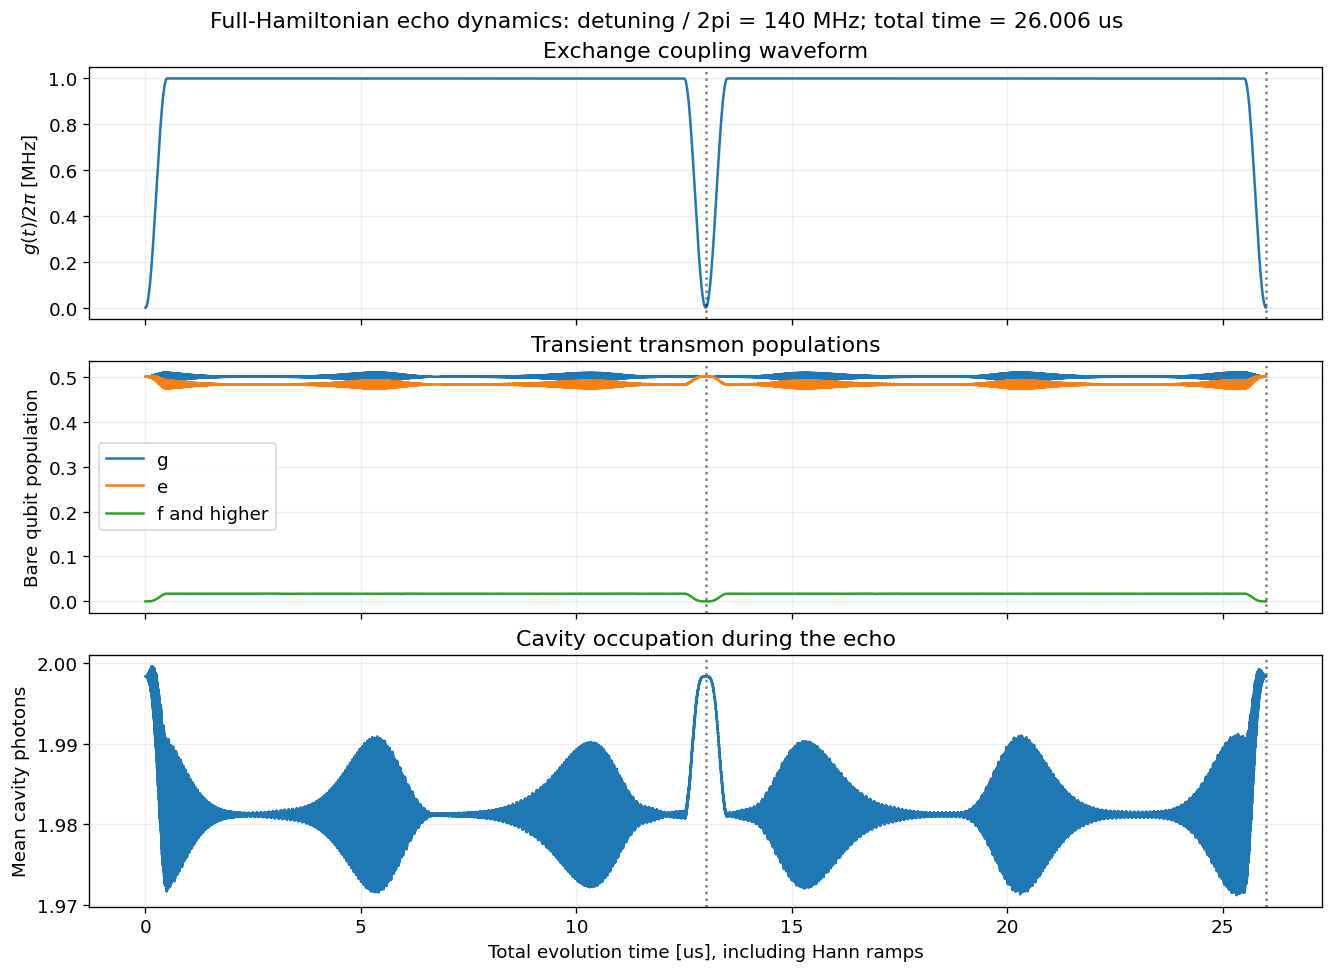

In [9]:
# Follow one coherent cavity input and qubit |+> throughout both lobes and pulses.
n = np.arange(n_max+1)
cavity_coefficients = np.exp(-abs(coherent_alpha)**2/2)*coherent_alpha**n/np.sqrt(factorial(n))
omitted_probability = 1-np.sum(abs(cavity_coefficients)**2)
cavity_coefficients /= np.linalg.norm(cavity_coefficients)
psi0 = np.zeros(cavity_levels*qubit_levels, dtype=complex)
for photon in range(n_max+1):
    for q in [0, 1]:
        psi0[photon*qubit_levels+q] = cavity_coefficients[photon]*input_qubit[q]
psi = psi0.copy()
times = [0.]
states_qubit_frame = [psi.copy()]
envelope = [0.]
time = 0.

for lobe_index in range(2):
    for step_index in range(len(pulse_blocks[0]['up_steps'])):
        for block in pulse_blocks:
            indices = block['indices']
            psi[indices] = block['up_steps'][step_index] @ psi[indices]
        time = lobe_index*lobe_time_us+(step_index+1)*dt_fine
        times.append(time)
        states_qubit_frame.append(np.exp(2j*np.pi*pulse_detuning_mhz*q_number*time)*psi)
        envelope.append(g_mhz*(1-np.cos(np.pi*(step_index+1)*dt_fine/ramp_time_us))/2)
    flat_start = psi.copy()
    for elapsed in np.linspace(0, flat_time_us, flat_trace_samples)[1:]:
        for block in pulse_blocks:
            indices = block['indices']
            vectors, values = block['flat_vectors'], block['flat_values']
            psi[indices] = vectors @ (np.exp(-2j*np.pi*values*elapsed)*(vectors.T @ flat_start[indices]))
        time = lobe_index*lobe_time_us+ramp_time_us+elapsed
        times.append(time)
        states_qubit_frame.append(np.exp(2j*np.pi*pulse_detuning_mhz*q_number*time)*psi)
        envelope.append(g_mhz)
    for step_index in range(len(pulse_blocks[0]['up_steps'])):
        for block in pulse_blocks:
            indices = block['indices']
            psi[indices] = block['up_steps'][-1-step_index] @ psi[indices]
        time = lobe_index*lobe_time_us+ramp_time_us+flat_time_us+(step_index+1)*dt_fine
        times.append(time)
        states_qubit_frame.append(np.exp(2j*np.pi*pulse_detuning_mhz*q_number*time)*psi)
        envelope.append(g_mhz*(1+np.cos(np.pi*(step_index+1)*dt_fine/ramp_time_us))/2)
    time = (lobe_index+1)*lobe_time_us
    psi = detuned_frame_pulses[lobe_index] @ psi
    times.append(time)  # duplicate time displays an instantaneous ideal X
    states_qubit_frame.append(np.exp(2j*np.pi*pulse_detuning_mhz*q_number*time)*psi)
    envelope.append(0.)

times = np.array(times)
states_qubit_frame = np.array(states_qubit_frame)
state_tensor = states_qubit_frame.reshape(len(times), cavity_levels, qubit_levels)
qubit_populations = np.sum(abs(state_tensor)**2, axis=1)
cavity_populations = np.sum(abs(state_tensor)**2, axis=2)
mean_photons = cavity_populations @ np.arange(cavity_levels)
final_matrix = state_tensor[-1]
rho_cavity = final_matrix @ final_matrix.conj().T
purity = np.trace(rho_cavity @ rho_cavity).real

target_spectrum = np.zeros(cavity_levels, dtype=complex)
target_spectrum[:n_max+1] = cavity_coefficients*ideal_amplitudes
# An ideal quadratic phase matched only to n=0,1,2 separates non-Kerr distortion.
quadratic_cycles = (echo_phase_cycles[0]+n*(echo_phase_cycles[1]-echo_phase_cycles[0])
                    +np.diff(echo_phase_cycles, n=2)[0]*n*(n-1)/2)
target_kerr = np.zeros(cavity_levels, dtype=complex)
target_kerr[:n_max+1] = cavity_coefficients*np.exp(-2j*np.pi*quadratic_cycles)
fidelity_spectrum = np.vdot(target_spectrum, rho_cavity @ target_spectrum).real
fidelity_kerr = np.vdot(target_kerr, rho_cavity @ target_kerr).real
trajectory_endpoint_error = np.max(abs(states_qubit_frame[-1]-echo_unitary @ psi0))
print(f'MEASURED: {len(times)} full-H time samples, '
      f'{states_qubit_frame.size} state amplitudes; endpoint difference={trajectory_endpoint_error:.3g}')
print(f'Initial coherent-state probability omitted above n_max: {omitted_probability:.6g}')
print(f'Final cavity purity={purity:.9f}; fidelity to full adiabatic spectrum={fidelity_spectrum:.9f}; '
      f'fidelity to quadratic Kerr={fidelity_kerr:.9f}')

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(times, envelope)
axes[0].set_ylabel(r'$g(t)/2\pi$ [MHz]')
axes[1].plot(times, qubit_populations[:, 0], label='g')
axes[1].plot(times, qubit_populations[:, 1], label='e')
axes[1].plot(times, qubit_populations[:, 2:].sum(axis=1), label='f and higher')
axes[1].set_ylabel('Bare qubit population')
axes[1].legend()
axes[2].plot(times, mean_photons)
axes[2].set_ylabel('Mean cavity photons')
axes[2].set_xlabel('Total evolution time [us], including Hann ramps')
for ax in axes:
    for pulse_time in [lobe_time_us, 2*lobe_time_us]:
        ax.axvline(pulse_time, ls=':', color='black', alpha=0.5)
    ax.grid(alpha=0.2)
axes[0].set_title('Exchange coupling waveform')
axes[1].set_title('Transient transmon populations')
axes[2].set_title('Cavity occupation during the echo')
fig.suptitle(f'Full-Hamiltonian echo dynamics: detuning / 2pi = {pulse_detuning_mhz:g} MHz; total time = {2*lobe_time_us:.3f} us')
fig.savefig(output_dir / 'full_time_domain_traces.png', dpi=200)
plt.show()
pd.DataFrame({'time_us': times, 'g_MHz': envelope,
              'Pg': qubit_populations[:, 0], 'Pe': qubit_populations[:, 1],
              'Pf_and_higher': qubit_populations[:, 2:].sum(axis=1),
              'mean_cavity_photons': mean_photons}).to_csv(output_dir / 'time_traces.csv', index=False)

TITLED: full_time_domain_phase_and_return.png: 2 panels


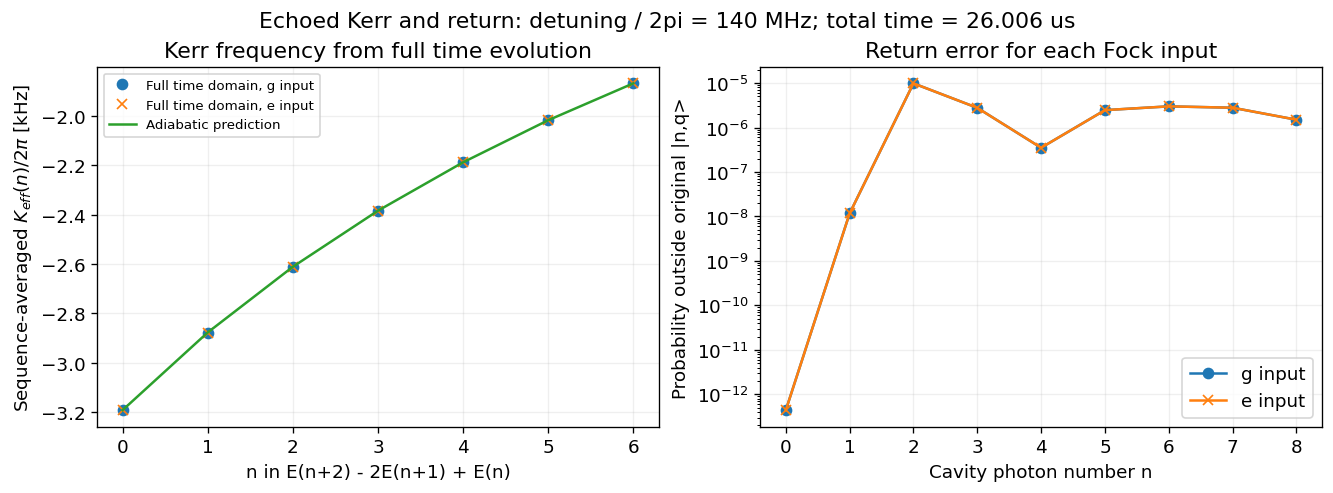

In [10]:
# Infer photon-dependent Kerr frequencies directly from the full time-domain amplitudes.
actual_phases = np.unwrap(np.angle(diagonal_amplitudes), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
frequency_n = np.arange(n_max-1)
time_total = 2*lobe_time_us
for q, label, marker in [(0, 'Full time domain, g input', 'o'), (1, 'Full time domain, e input', 'x')]:
    inferred_khz = -1e3*np.diff(actual_phases[:, q], n=2)/(2*np.pi*time_total)
    axes[0].plot(frequency_n, inferred_khz, marker, label=label)
axes[0].plot(frequency_n, 1e3*np.diff(echo_phase_cycles, n=2)/time_total,
             '-', label='Adiabatic prediction')
axes[0].set_xlabel('n in E(n+2) - 2E(n+1) + E(n)')
axes[0].set_ylabel(r'Sequence-averaged $K_{eff}(n)/2\pi$ [kHz]')
axes[0].legend(fontsize=8)
axes[1].semilogy(n, np.maximum(return_error[:, 0], 1e-16), 'o-', label='g input')
axes[1].semilogy(n, np.maximum(return_error[:, 1], 1e-16), 'x-', label='e input')
axes[1].set_xlabel('Cavity photon number n')
axes[1].set_ylabel('Probability outside original |n,q>')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
axes[0].set_title('Kerr frequency from full time evolution')
axes[1].set_title('Return error for each Fock input')
fig.suptitle(f'Echoed Kerr and return: detuning / 2pi = {pulse_detuning_mhz:g} MHz; total time = {2*lobe_time_us:.3f} us')
fig.savefig(output_dir / 'full_time_domain_phase_and_return.png', dpi=200)
plt.show()

## Kerr frequency and fidelity over n=0…8

$$
|\psi_q\rangle=c_g|g\rangle+c_e|e\rangle,\qquad
\boxed{U_{\mathrm{target}}=U_K\otimes I_{ge}}.
$$

The primary metric is the **joint d=18 gate fidelity**, including qubit coherences.
An accurate cavity gate only for a qubit prepared in g does not meet the requirement.

$$
U_K(T)=\exp\!\left[-i2\pi T\left(\nu n+\frac{k_{\mathrm{eff}}}2n(n-1)\right)\right],
\qquad k_{\mathrm{eff}}\equiv K_{\mathrm{eff}}/2\pi\ \text{in kHz}.
$$

$k_{\mathrm{eff}}$ averages over the **whole sequence, ramps included**. Fit $\nu,k_{\mathrm{eff}}$
over all nine Fock states; also show the target inferred only from n=0,1,2.

$$
M=P U_K^\dagger U_{\mathrm{actual}}P,\qquad
F_{\mathrm{avg}}=\frac{\mathrm{Tr}(M^\dagger M)+|\mathrm{Tr}M|^2}{d(d+1)}.
$$

d=9 for one fixed qubit input; d=18 for both g/e. Leakage counts as error.
The fit uses a periodic grid plus eight local starts. At fixed T, equivalent fitted
rates differ by $1/T$; the plots show the representative closest to zero.

TITLED: Kerr_frequency_and_fidelity.png: 2 panels


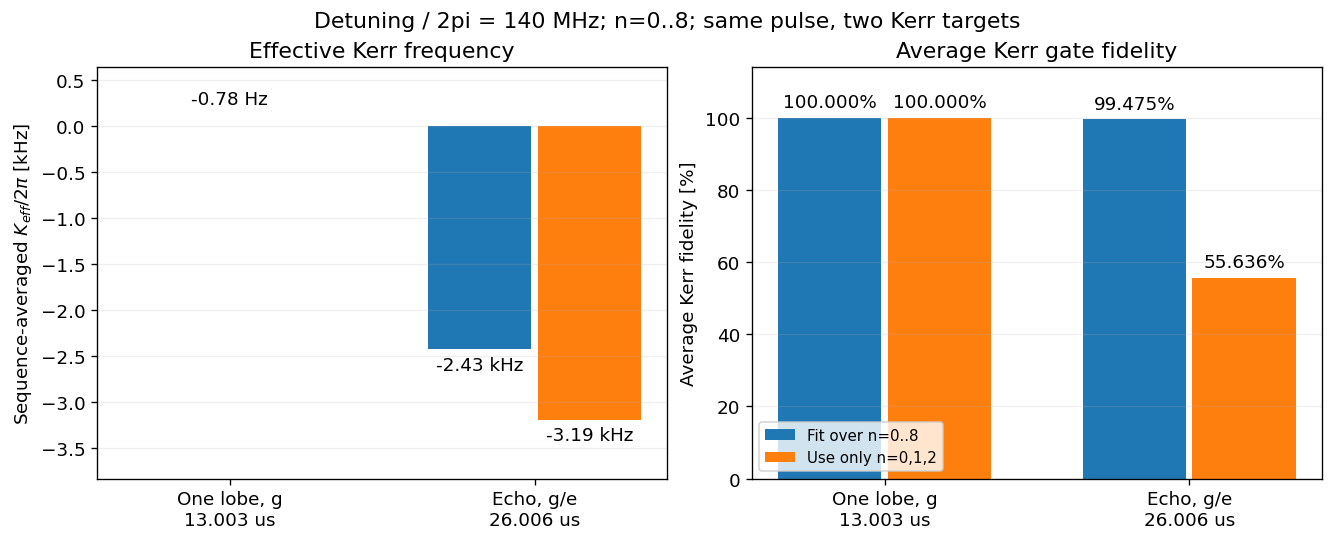

COMPARED Kerr fidelity: all 9 ground-input columns and 18 echo g/e columns, using 10 x 5 cutoffs


In [11]:
def kerr_gate_metrics(unitary, indices, photons, reference_cycles=None):
    """Unconditional subspace fidelity, including leakage and all matrix elements."""
    submatrix = unitary[np.ix_(indices, indices)]
    diagonal = np.diag(submatrix)
    dimension = len(indices)
    pair = photons*(photons-1)/2
    survival = np.sum(abs(submatrix)**2)/dimension

    def fidelity_for_phase(phase):
        trace = np.sum(np.exp(1j*phase)*diagonal)
        process = abs(trace)**2/dimension**2
        average = (dimension*survival+abs(trace)**2)/(dimension*(dimension+1))
        return process, average

    grid = np.linspace(-np.pi, np.pi, 129, endpoint=False)
    # Sum the two qubit branches for each photon number when fitting an echo.
    distinct_n = np.arange(n_max+1)
    coefficients = np.array([diagonal[photons == photon].sum() for photon in distinct_n])
    linear_factors = np.exp(1j*grid[:, None]*distinct_n)
    kerr_factors = np.exp(1j*grid[:, None]*distinct_n*(distinct_n-1)/2)
    grid_trace = (linear_factors*coefficients) @ kerr_factors.T
    seed_indices = np.argpartition(abs(grid_trace).ravel(), -8)[-8:]

    def objective(parameters):
        phase = parameters[0]*photons+parameters[1]*pair
        terms = diagonal*np.exp(1j*phase)
        trace = terms.sum()
        derivatives = 1j*np.array([np.sum(photons*terms), np.sum(pair*terms)])
        gradient = -2*np.real(trace.conjugate()*derivatives)/dimension**2
        return -abs(trace)**2/dimension**2, gradient

    best = None
    for seed_index in seed_indices:
        i, j = np.unravel_index(seed_index, grid_trace.shape)
        fit = minimize(objective, [grid[i], grid[j]], jac=True, method='BFGS',
                       options={'gtol': 1e-10, 'maxiter': 200})
        if best is None or fit.fun < best.fun:
            best = fit
    linear, theta = np.angle(np.exp(1j*best.x))
    process_fit, average_fit = fidelity_for_phase(linear*photons+theta*pair)
    result = {'F_process_fitted_Kerr': process_fit, 'F_avg_fitted_Kerr': average_fit,
              'fitted_linear_rad': linear, 'fitted_Kerr_angle_rad': theta,
              'mean_subspace_survival': survival,
              'max_product_return_error': np.max(np.maximum(0., 1-abs(diagonal)**2))}
    if reference_cycles is not None:
        beta = 2*np.pi*(reference_cycles[1]-reference_cycles[0])
        angle = 2*np.pi*np.diff(reference_cycles, n=2)[0]
        process_reference, average_reference = fidelity_for_phase(beta*photons+angle*pair)
        result.update({'F_process_n012_Kerr': process_reference,
                       'F_avg_n012_Kerr': average_reference,
                       'n012_Kerr_angle_rad': angle})
    return result


photon_labels_echo = np.repeat(np.arange(n_max+1), 2)
ground_indices = np.arange(n_max+1)*qubit_levels
echo_metrics = kerr_gate_metrics(echo_unitary, input_indices, photon_labels_echo, echo_phase_cycles)
# Compare a single interaction lobe with the qubit initially in g, using the same ramps.
ground_rotation = np.exp(2j*np.pi*pulse_detuning_mhz*q_number*lobe_time_us)
ground_unitary = ground_rotation[:, None]*lobe
ground_metrics = kerr_gate_metrics(ground_unitary, ground_indices, np.arange(n_max+1),
                                   phase_grid[:n_max+1, 0])
echo_g_metrics = kerr_gate_metrics(echo_unitary, ground_indices, np.arange(n_max+1), echo_phase_cycles)
echo_e_metrics = kerr_gate_metrics(echo_unitary, ground_indices+1, np.arange(n_max+1), echo_phase_cycles)
main_kerr_table = pd.DataFrame([
    {'operation': 'One lobe, qubit g', 'duration_us': lobe_time_us, **ground_metrics},
    {'operation': 'Echo, input g', 'duration_us': 2*lobe_time_us, **echo_g_metrics},
    {'operation': 'Echo, input e', 'duration_us': 2*lobe_time_us, **echo_e_metrics},
    {'operation': 'Echo, both g/e', 'duration_us': 2*lobe_time_us, **echo_metrics}])
main_kerr_table['fitted_Kerr_kHz'] = 1e3*main_kerr_table.fitted_Kerr_angle_rad/(2*np.pi*main_kerr_table.duration_us)
main_kerr_table['n012_Kerr_kHz'] = 1e3*main_kerr_table.n012_Kerr_angle_rad/(2*np.pi*main_kerr_table.duration_us)
main_kerr_table.to_csv(output_dir / 'main_Kerr_gate_fidelity.csv', index=False)

comparison = main_kerr_table.iloc[[0, 3]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
x = np.arange(len(comparison))
for shift, rate_column, fidelity_column, label, color in [
    (-0.18, 'fitted_Kerr_kHz', 'F_avg_fitted_Kerr', 'Fit over n=0..8', 'tab:blue'),
    (+0.18, 'n012_Kerr_kHz', 'F_avg_n012_Kerr', 'Use only n=0,1,2', 'tab:orange')]:
    bars = axes[0].bar(x+shift, comparison[rate_column], width=0.34, label=label, color=color)
    axes[0].bar_label(bars, labels=[f'{v:+.3g} kHz' if abs(v)>=0.001 else '' for v in comparison[rate_column]], padding=4)
    bars = axes[1].bar(x+shift, comparison[fidelity_column]*100, width=0.34, label=label, color=color)
    axes[1].bar_label(bars, labels=[f'{v:.3f}%' for v in comparison[fidelity_column]*100], padding=4)
axes[0].set_ylabel(r'Sequence-averaged $K_{eff}/2\pi$ [kHz]')
all_rates = np.r_[comparison.fitted_Kerr_kHz, comparison.n012_Kerr_kHz]
rate_min, rate_max = min(0., all_rates.min()), max(0., all_rates.max())
rate_margin = 0.2*max(rate_max-rate_min, 1e-4)
axes[0].set_ylim(rate_min-rate_margin, rate_max+rate_margin)
for x_position, value in enumerate(comparison.fitted_Kerr_kHz):
    if abs(value)<0.001:
        axes[0].text(x_position, rate_margin*0.3, f'{value*1e3:+.2f} Hz', ha='center', va='bottom')
axes[1].set_ylabel('Average Kerr fidelity [%]')
axes[1].set_ylim(0, 114)
axes[1].legend(loc='lower left', fontsize=9)
for ax in axes:
    ax.set_xticks(x, ['One lobe, g\n'+f'{lobe_time_us:.3f} us',
                      'Echo, g/e\n'+f'{2*lobe_time_us:.3f} us'])
    ax.grid(axis='y', alpha=0.2)
fig.suptitle(f'Detuning / 2pi = {pulse_detuning_mhz:g} MHz; n=0..{n_max}; same pulse, two Kerr targets')
axes[0].set_title('Effective Kerr frequency')
axes[1].set_title('Average Kerr gate fidelity')
fig.savefig(output_dir / 'Kerr_frequency_and_fidelity.png', dpi=200)
plt.show()
print(f'COMPARED Kerr fidelity: all {len(ground_indices)} ground-input columns and '
      f'{len(input_indices)} echo g/e columns, using {cavity_levels} x {qubit_levels} cutoffs')

## Ramp duration: return error, Kerr frequency, fidelity

$$
T_{\mathrm{echo}}=2t_f+4t_r.
$$

Keep the flat top fixed; vary **each** Hann edge. Include the ramp's own nonlinear phase.
Return error measures nonadiabaticity; Kerr fidelity also measures nonquadratic phase.

TITLED: ramp_duration_study.png: 4 panels


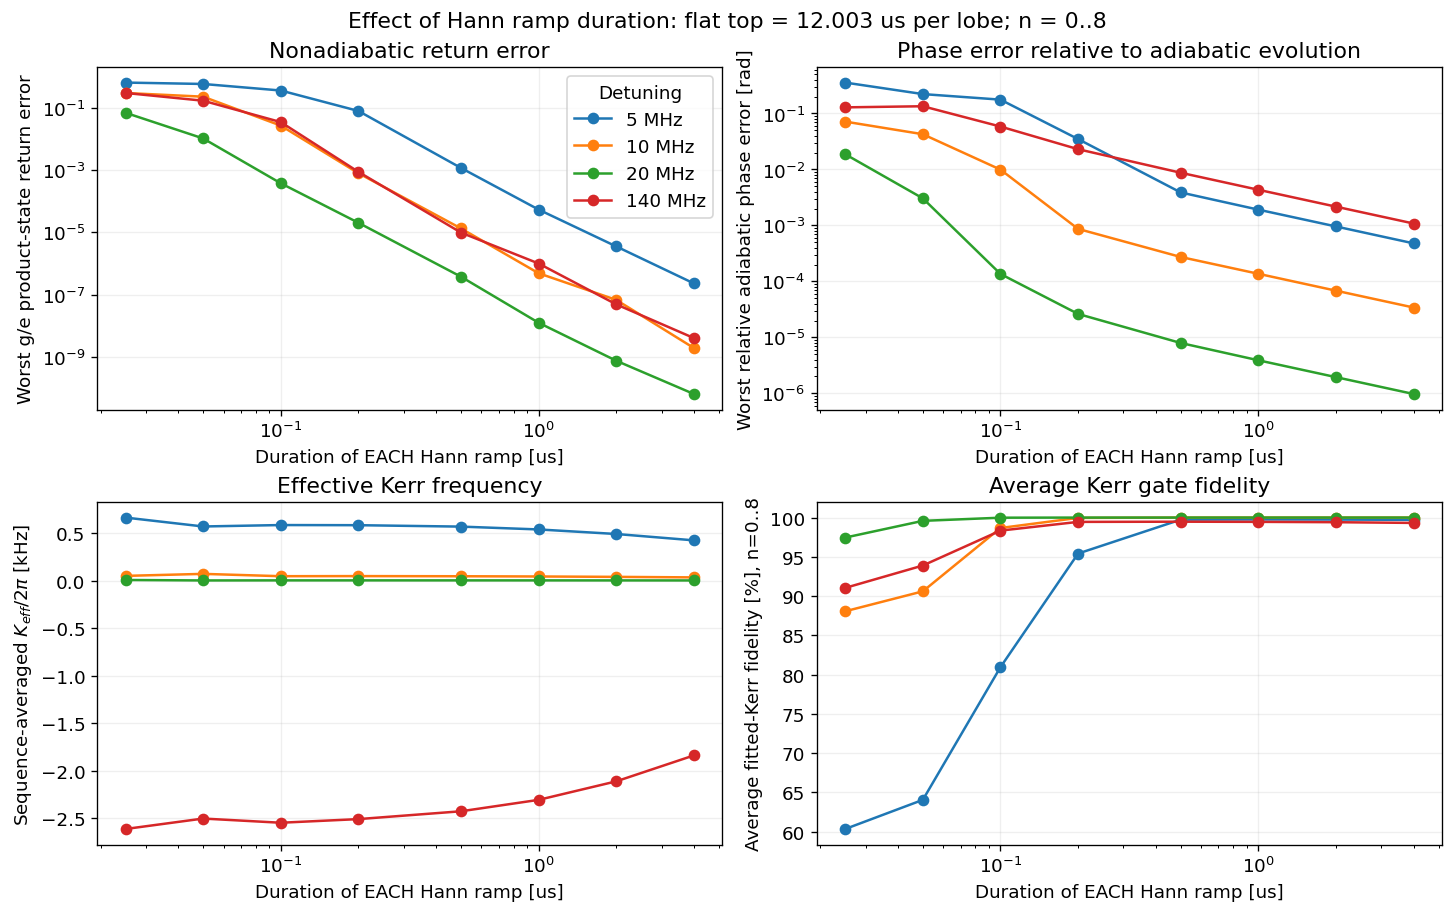

COMPARED ramp study: 32 cases, 576 g/e return amplitudes; 288 ground-input return amplitudes


In [12]:
ramp_rows = []
for delta in ramp_study_detunings_mhz:
    for ramp in ramp_study_times_us:
        F, integrals, _, _ = full_lobe(delta, cavity_levels, qubit_levels, fine_ramp_step_us,
                                       ramp_duration_us=ramp, keep_steps=False)
        U, _, numbers = echo_in_qubit_frame(F, delta, cavity_levels, qubit_levels,
                                            ramp_duration_us=ramp)
        duration = 2*ramp+flat_time_us
        integrals = integrals.reshape(cavity_levels, qubit_levels)
        cycles = integrals[:n_max+1, 0]+integrals[:n_max+1, 1]-delta*duration
        expected = -np.exp(-2j*np.pi*cycles)
        diagonal = np.diag(U)[input_indices].reshape(n_max+1, 2)
        ratio = diagonal/expected[:, None]
        relative_phase_error = np.angle(ratio*ratio[0].conj())
        ground_diag = np.diag(F)[ground_indices]
        ground_phase_error = np.angle(ground_diag*np.exp(2j*np.pi*integrals[:n_max+1, 0]))
        metrics = kerr_gate_metrics(U, input_indices, photon_labels_echo, cycles)
        ground_U = np.exp(2j*np.pi*delta*numbers*duration)[:, None]*F
        gm = kerr_gate_metrics(ground_U, ground_indices, np.arange(n_max+1),
                               integrals[:n_max+1, 0])
        ramp_rows.append({'delta_MHz': delta, 'ramp_us': ramp, 'echo_total_us': 2*duration,
                          'ground_return_error': np.max(np.maximum(0., 1-abs(ground_diag)**2)),
                          'ground_adiabatic_phase_error_rad': np.max(abs(ground_phase_error)),
                          'echo_adiabatic_relative_phase_error_rad': np.max(abs(relative_phase_error)),
                          'ground_F_avg_fitted_Kerr': gm['F_avg_fitted_Kerr'],
                          'ground_fitted_Kerr_angle_rad': gm['fitted_Kerr_angle_rad'],
                          **metrics})
    print(f'Ramp sweep running: completed delta={delta:g} MHz, {len(ramp_rows)} full-H cases', flush=True)
ramp_table = pd.DataFrame(ramp_rows)
assert len(ramp_table) == len(ramp_study_detunings_mhz)*len(ramp_study_times_us)
ramp_table['fitted_Kerr_kHz'] = 1e3*ramp_table.fitted_Kerr_angle_rad/(2*np.pi*ramp_table.echo_total_us)
ramp_table['ground_duration_us'] = ramp_table.echo_total_us/2
ramp_table['ground_fitted_Kerr_kHz'] = 1e3*ramp_table.ground_fitted_Kerr_angle_rad/(2*np.pi*ramp_table.ground_duration_us)
ramp_table['n012_Kerr_kHz'] = 1e3*ramp_table.n012_Kerr_angle_rad/(2*np.pi*ramp_table.echo_total_us)
ramp_table.to_csv(output_dir / 'ramp_duration_study.csv', index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), constrained_layout=True)
axes = axes.ravel()
for delta in ramp_study_detunings_mhz:
    rows = ramp_table[ramp_table.delta_MHz == delta]
    axes[0].loglog(rows.ramp_us, rows.max_product_return_error, 'o-', label=f'{delta:g} MHz')
    axes[1].loglog(rows.ramp_us, rows.echo_adiabatic_relative_phase_error_rad, 'o-')
    axes[2].semilogx(rows.ramp_us, rows.fitted_Kerr_kHz, 'o-')
    axes[3].semilogx(rows.ramp_us, rows.F_avg_fitted_Kerr*100, 'o-')
axes[0].set_ylabel('Worst g/e product-state return error')
axes[1].set_ylabel('Worst relative adiabatic phase error [rad]')
axes[2].set_ylabel(r'Sequence-averaged $K_{eff}/2\pi$ [kHz]')
axes[3].set_ylabel('Average fitted-Kerr fidelity [%], n=0..8')
axes[0].legend(title='Detuning')
for ax in axes:
    ax.set_xlabel('Duration of EACH Hann ramp [us]')
    ax.grid(alpha=0.2)
axes[0].set_title('Nonadiabatic return error')
axes[1].set_title('Phase error relative to adiabatic evolution')
axes[2].set_title('Effective Kerr frequency')
axes[3].set_title('Average Kerr gate fidelity')
fig.suptitle(f'Effect of Hann ramp duration: flat top = {flat_time_us:g} us per lobe; n = 0..{n_max}')
fig.savefig(output_dir / 'ramp_duration_study.png', dpi=200)
plt.show()
print(f'COMPARED ramp study: {len(ramp_table)} cases, '
      f'{len(ramp_table)*len(input_indices)} g/e return amplitudes; '
      f'{len(ramp_table)*len(ground_indices)} ground-input return amplitudes')

## Apparent divergences → avoided crossings

```text
delta/2π      resonant exchange                 perturbative pole
 75 MHz       |g,n> ↔ |f,n−2>                   Kg and chi prime
150 MHz       |e,n> ↔ |f,n−1>                   chi prime; Kg(0) finite
225 MHz       |e,n> ↔ |h,n−2>                   chi prime; Kg(0) finite
```

The finite Hamiltonian stays finite. Spectral labels are ambiguous at exact bare
degeneracy, so spectral curves have a gap there. **Physical pulse simulations include
the exact resonance centers.** Narrow multi-excitation gaps can require long ramps.
Higher Fock inputs also access ground ↔ h at 150 MHz and ground ↔ i at 225 MHz.

TITLED: near_resonance_spectra_and_fidelity.png: 9 panels


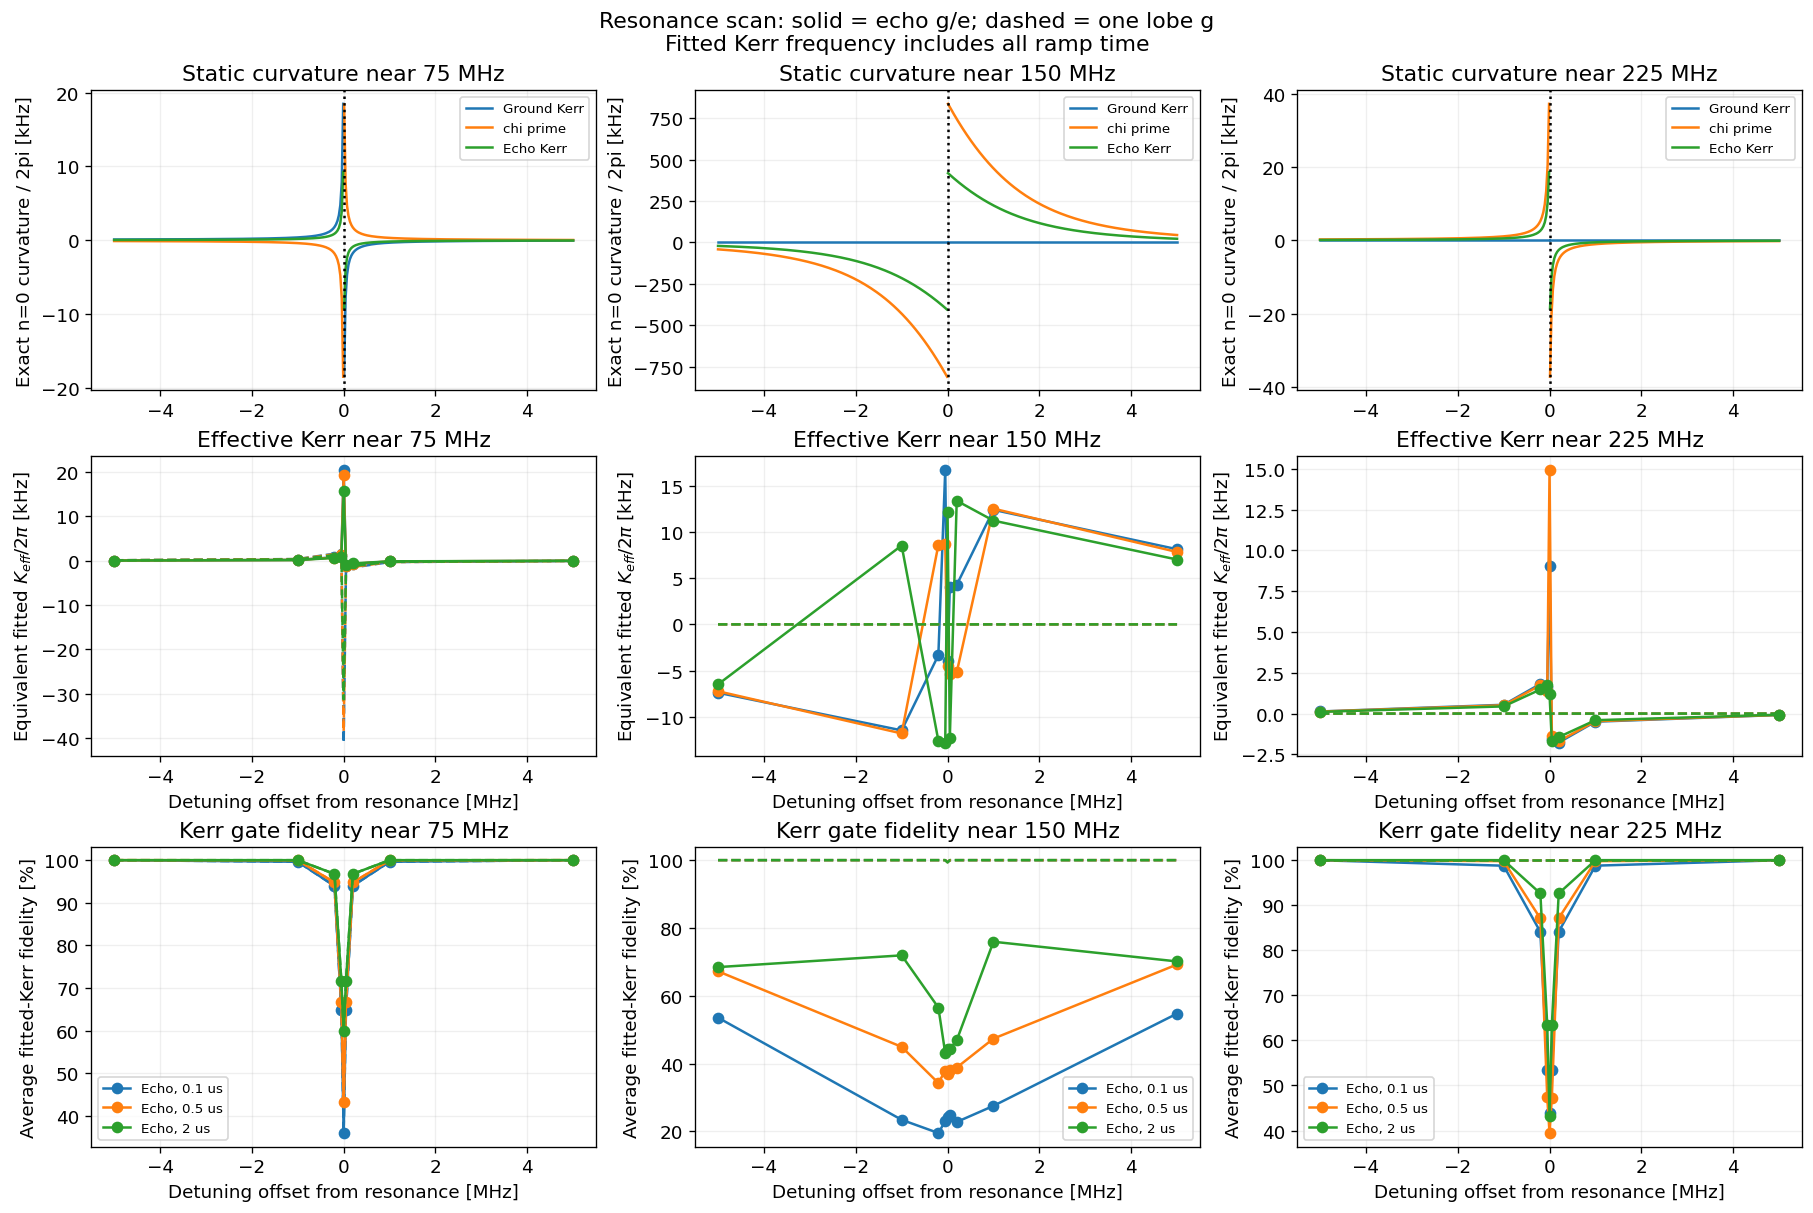

TITLED: near_resonance_ramp_effect.png: 9 panels


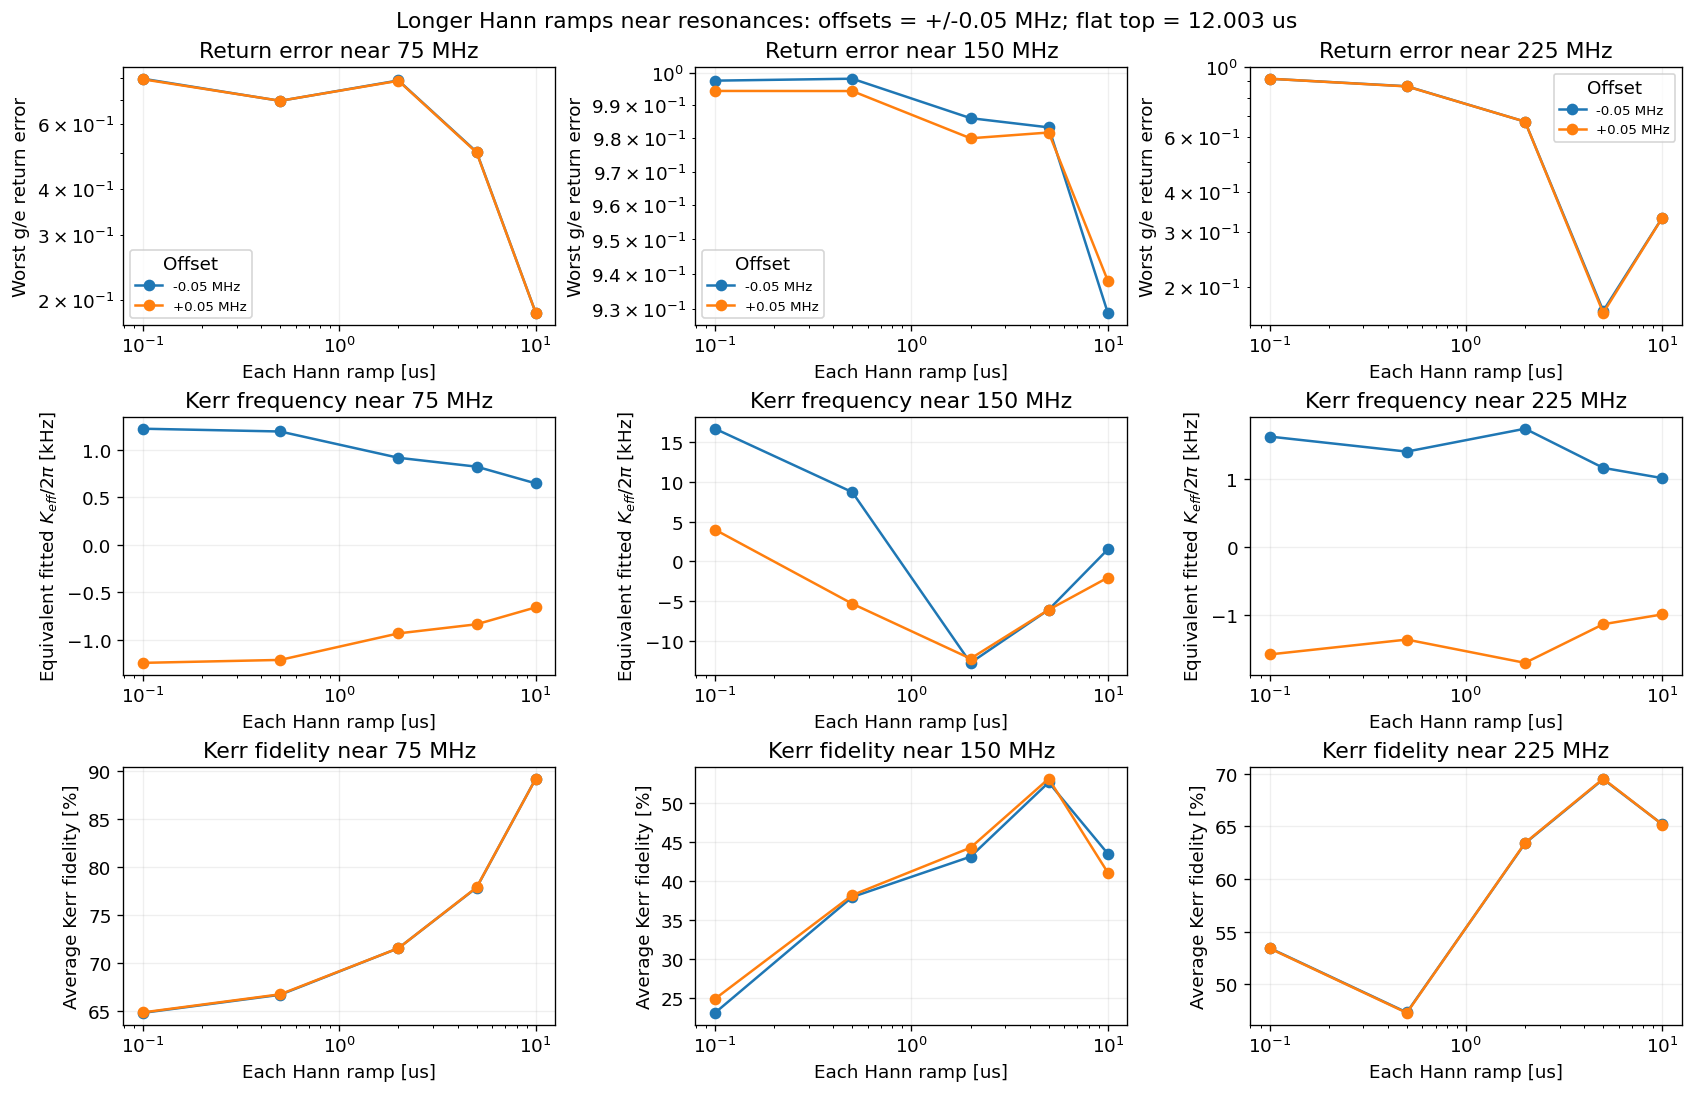

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), constrained_layout=True)
spectral_near_rows = []
for column, center in enumerate(resonance_centers_mhz):
    offsets = np.r_[np.linspace(-5, -0.01, 160), np.nan, np.linspace(0.01, 5, 160)]
    rates = np.full((len(offsets), 3), np.nan)
    for row, offset in enumerate(offsets):
        if not np.isfinite(offset):
            continue
        energies, overlaps = dressed_ladders(center+offset)
        kg, cp, ke = ladder_rates(energies)
        rates[row] = [kg[0], cp[0], ke[0]]
        spectral_near_rows.append({'center_MHz': center, 'offset_MHz': offset,
                                  'Kg_kHz': 1e3*kg[0], 'chi_prime_kHz': 1e3*cp[0],
                                  'Kecho_kHz': 1e3*ke[0], 'min_bare_overlap': overlaps.min()})
    for k, label in enumerate(['Ground Kerr', 'chi prime', 'Echo Kerr']):
        axes[0, column].plot(offsets, rates[:, k]*1e3, label=label)
    axes[0, column].set_title(f'Near delta = {center:g} MHz')
    axes[0, column].set_ylabel('Exact n=0 curvature / 2pi [kHz]')
    axes[0, column].axvline(0, ls=':', color='black')
    axes[0, column].legend(fontsize=8)
    axes[0, column].grid(alpha=0.2)

resonance_rows = []
for center in resonance_centers_mhz:
    for offset in resonance_offsets_mhz:
        for ramp in resonance_ramp_times_us:
            delta = center+offset
            F, _, _, _ = full_lobe(delta, cavity_levels, qubit_levels, fine_ramp_step_us,
                                   ramp_duration_us=ramp, keep_steps=False)
            U, _, _ = echo_in_qubit_frame(F, delta, cavity_levels, qubit_levels,
                                          ramp_duration_us=ramp)
            metrics = kerr_gate_metrics(U, input_indices, photon_labels_echo)
            ground_duration = 2*ramp+flat_time_us
            bare_numbers = np.tile(np.arange(qubit_levels), cavity_levels)
            Ug = np.exp(2j*np.pi*delta*bare_numbers*ground_duration)[:, None]*F
            gm = kerr_gate_metrics(Ug, ground_indices, np.arange(n_max+1))
            resonance_rows.append({'center_MHz': center, 'offset_MHz': offset,
                                   'delta_MHz': delta, 'ramp_us': ramp,
                                   'echo_total_us': 2*ground_duration,
                                   'ground_F_avg_fitted_Kerr': gm['F_avg_fitted_Kerr'],
                                   'ground_fitted_Kerr_angle_rad': gm['fitted_Kerr_angle_rad'],
                                   'ground_return_error': gm['max_product_return_error'], **metrics})
    print(f'Resonance scan running: completed center={center:g} MHz; '
          f'{len(resonance_rows)} full-H cases', flush=True)

# Test longer ramps on both sides of the narrow two-excitation crossings.
for center in resonance_centers_mhz:
    for offset in [-0.05, 0.05]:
        for ramp in long_resonance_ramp_times_us:
            delta = center+offset
            F, _, _, _ = full_lobe(delta, cavity_levels, qubit_levels, fine_ramp_step_us,
                                   ramp_duration_us=ramp, keep_steps=False)
            U, _, _ = echo_in_qubit_frame(F, delta, cavity_levels, qubit_levels,
                                          ramp_duration_us=ramp)
            metrics = kerr_gate_metrics(U, input_indices, photon_labels_echo)
            ground_duration = 2*ramp+flat_time_us
            bare_numbers = np.tile(np.arange(qubit_levels), cavity_levels)
            Ug = np.exp(2j*np.pi*delta*bare_numbers*ground_duration)[:, None]*F
            gm = kerr_gate_metrics(Ug, ground_indices, np.arange(n_max+1))
            resonance_rows.append({'center_MHz': center, 'offset_MHz': offset,
                                   'delta_MHz': delta, 'ramp_us': ramp,
                                   'echo_total_us': 2*ground_duration,
                                   'ground_F_avg_fitted_Kerr': gm['F_avg_fitted_Kerr'],
                                   'ground_fitted_Kerr_angle_rad': gm['fitted_Kerr_angle_rad'],
                                   'ground_return_error': gm['max_product_return_error'], **metrics})
    print(f'Long-ramp scan running: completed center={center:g} MHz', flush=True)
resonance_table = pd.DataFrame(resonance_rows)
expected_resonance_cases = len(resonance_centers_mhz)*(
    len(resonance_offsets_mhz)*len(resonance_ramp_times_us)+2*len(long_resonance_ramp_times_us))
assert len(resonance_table) == expected_resonance_cases
resonance_table['fitted_Kerr_kHz'] = 1e3*resonance_table.fitted_Kerr_angle_rad/(2*np.pi*resonance_table.echo_total_us)
resonance_table['ground_duration_us'] = resonance_table.echo_total_us/2
resonance_table['ground_fitted_Kerr_kHz'] = 1e3*resonance_table.ground_fitted_Kerr_angle_rad/(2*np.pi*resonance_table.ground_duration_us)
resonance_table.to_csv(output_dir / 'near_resonance_time_domain.csv', index=False)
pd.DataFrame(spectral_near_rows).to_csv(output_dir / 'near_resonance_exact_spectra.csv', index=False)
for column, center in enumerate(resonance_centers_mhz):
    for ramp in resonance_ramp_times_us:
        rows = resonance_table[(resonance_table.center_MHz == center) &
                               (resonance_table.ramp_us == ramp)].sort_values('offset_MHz')
        line, = axes[2, column].plot(rows.offset_MHz, rows.F_avg_fitted_Kerr*100, 'o-',
                                    label=f'Echo, {ramp:g} us')
        color = line.get_color()
        axes[2, column].plot(rows.offset_MHz, rows.ground_F_avg_fitted_Kerr*100, '--', color=color)
        axes[1, column].plot(rows.offset_MHz, rows.fitted_Kerr_kHz, 'o-', color=color)
        axes[1, column].plot(rows.offset_MHz, rows.ground_fitted_Kerr_kHz, '--', color=color)
    axes[1, column].set_ylabel(r'Equivalent fitted $K_{eff}/2\pi$ [kHz]')
    axes[2, column].set_ylabel('Average fitted-Kerr fidelity [%]')
    axes[2, column].legend(fontsize=8)
    for row in [1, 2]:
        axes[row, column].set_xlabel('Detuning offset from resonance [MHz]')
        axes[row, column].grid(alpha=0.2)
fig.suptitle('Solid: echo g/e; dashed: one lobe g. Fitted frequency uses total time, ramps included.')
for column, center in enumerate(resonance_centers_mhz):
    axes[0, column].set_title(f'Static curvature near {center:g} MHz')
    axes[1, column].set_title(f'Effective Kerr near {center:g} MHz')
    axes[2, column].set_title(f'Kerr gate fidelity near {center:g} MHz')
fig.suptitle('Resonance scan: solid = echo g/e; dashed = one lobe g\nFitted Kerr frequency includes all ramp time')
fig.savefig(output_dir / 'near_resonance_spectra_and_fidelity.png', dpi=200)
plt.show()
print(f'COMPARED near resonances: {len(spectral_near_rows)} finite exact spectra and '
      f'{len(resonance_table)} full-H pulse cases, '
      f'{len(resonance_table)*len(input_indices)} g/e return amplitudes, '
      'including all 3 exact resonance centers')

# Both sides of each resonance, with ramp durations extending to 10 us.
fig, axes = plt.subplots(3, 3, figsize=(14, 9), constrained_layout=True)
for column, center in enumerate(resonance_centers_mhz):
    for offset in [-0.05, 0.05]:
        rows = resonance_table[(resonance_table.center_MHz == center) &
                               np.isclose(resonance_table.offset_MHz, offset)].sort_values('ramp_us')
        axes[0, column].loglog(rows.ramp_us, rows.max_product_return_error, 'o-', label=f'{offset:+g} MHz')
        axes[1, column].semilogx(rows.ramp_us, rows.fitted_Kerr_kHz, 'o-')
        axes[2, column].semilogx(rows.ramp_us, rows.F_avg_fitted_Kerr*100, 'o-')
    axes[0, column].set_title(f'Near {center:g} MHz resonance')
    axes[0, column].set_ylabel('Worst g/e return error')
    axes[0, column].legend(title='Offset', fontsize=8)
    axes[1, column].set_ylabel(r'Equivalent fitted $K_{eff}/2\pi$ [kHz]')
    axes[2, column].set_ylabel('Average Kerr fidelity [%]')
    for row in range(3):
        axes[row, column].set_xlabel('Each Hann ramp [us]')
        axes[row, column].grid(alpha=0.2)
for column, center in enumerate(resonance_centers_mhz):
    axes[0, column].set_title(f'Return error near {center:g} MHz')
    axes[1, column].set_title(f'Kerr frequency near {center:g} MHz')
    axes[2, column].set_title(f'Kerr fidelity near {center:g} MHz')
fig.suptitle(f'Longer Hann ramps near resonances: offsets = +/-0.05 MHz; flat top = {flat_time_us:g} us')
fig.savefig(output_dir / 'near_resonance_ramp_effect.png', dpi=200)
plt.show()

## Checks

Independently integrate the oscillating frame; compare all requested input states and timestep resolutions.

In [14]:
# Independent solve_ivp calculation in both frames, on complete low-excitation blocks.
frame_check_delta_mhz = pulse_detuning_mhz
frame_check_ramp_us = 0.047
frame_check_flat_us = 0.053  # endpoint phase is not an integer multiple of 2pi
frame_check_time_us = 2*frame_check_ramp_us+frame_check_flat_us
frame_comparisons = 0
frame_error = 0.
frame_input_counts = 0

for total in range(4):
    qn = np.arange(total+1)
    nonlinear = np.diag(alpha_mhz*qn*(qn-1)/2)
    lower_q = np.diag(np.sqrt((total-qn[:-1])*(qn[:-1]+1)), 1)
    size = total+1
    def rhs(time, flat_state, rotating_qubit):
        if time < frame_check_ramp_us:
            amplitude = g_mhz*(1-np.cos(np.pi*time/frame_check_ramp_us))/2
        elif time < frame_check_ramp_us+frame_check_flat_us:
            amplitude = g_mhz
        else:
            elapsed = time-frame_check_ramp_us-frame_check_flat_us
            amplitude = g_mhz*(1+np.cos(np.pi*elapsed/frame_check_ramp_us))/2
        if rotating_qubit:
            phase = np.exp(-2j*np.pi*frame_check_delta_mhz*time)
            hamiltonian = nonlinear+amplitude*(phase*lower_q+phase.conjugate()*lower_q.T)
        else:
            hamiltonian = (nonlinear+np.diag(frame_check_delta_mhz*qn)
                           +amplitude*(lower_q+lower_q.T))
        return (-2j*np.pi*hamiltonian @ flat_state.reshape(size, size)).ravel()
    initial = np.eye(size, dtype=complex).ravel()
    solutions = []
    for rotating_qubit in [False, True]:
        solution = solve_ivp(rhs, (0, frame_check_time_us), initial,
                             args=(rotating_qubit,), method='DOP853',
                             rtol=2e-10, atol=2e-12, max_step=0.0005)
        assert solution.success and len(solution.t) > 10
        solutions.append(solution.y[:, -1].reshape(size, size))
    endpoint_rotation = np.exp(2j*np.pi*frame_check_delta_mhz*qn*frame_check_time_us)
    difference = solutions[1]-endpoint_rotation[:, None]*solutions[0]
    frame_error = max(frame_error, np.max(abs(difference)))
    frame_comparisons += difference.size
    frame_input_counts += size
assert frame_comparisons == 30 and frame_input_counts == 10
assert frame_error < 2e-6
print(f'COMPARED frames: {frame_comparisons} complex propagator elements, '
      f'{frame_input_counts} input states across 4 complete blocks; max error={frame_error:.6g}')

COMPARED frames: 30 complex propagator elements, 10 input states across 4 complete blocks; max error=2.10121e-08


In [15]:
# Check the pre-existing full QuTiP Hamiltonian on nonresonant reference points.
reference_count = 0
reference_error = 0.
for delta in [20., 130., 170.]:
    parameters = {'N_c': cavity_levels, 'N_q': qubit_levels,
                  'detuning': 2*np.pi*delta, 'gbs': 2*np.pi*g_mhz}
    reference = dchi_H(parameters, 2*np.pi*alpha_mhz)
    exact, _ = dressed_ladders(delta)
    for photon in range(n_max+1):
        for q in [0, 1]:
            value = reference['sorted_dict']['evals_sorted'][photon][q]
            assert value is not None, f'Missing legacy label: n={photon}, q={q}'
            reference_error = max(reference_error, abs(value/(2*np.pi)-exact[photon, q]))
            reference_count += 1
assert reference_count == 3*2*(n_max+1)
assert reference_error < 1e-8
print(f'COMPARED existing dchi_H: {reference_count} g/e dressed energies at 3 detunings; '
      f'max error={reference_error:.6g} MHz')

# Strict two-level JC has a closed-form solution: independent check of branch labels.
tls_count = 0
tls_error = 0.
for delta in [-20., -5., 5., 10., 20.]:
    energies, _ = dressed_ladders(delta, levels=2)
    sign = np.sign(delta)
    ground = (delta-sign*np.sqrt(delta**2+4*g_mhz**2*n))/2
    excited = (delta+sign*np.sqrt(delta**2+4*g_mhz**2*(n+1)))/2
    closed_form = np.column_stack([ground, excited])
    tls_error = max(tls_error, np.max(abs(energies-closed_form)))
    tls_count += energies.size
assert tls_count == 5*2*(n_max+1) and tls_error < 1e-10
print(f'COMPARED exact two-level JC: {tls_count} energies; max error={tls_error:.6g} MHz')

# Verify the conversion from the local chi_prime helper against B13g as printed.
delta = table_detunings_mhz
paper_prime = (4*g_mhz**4*K_mhz**2 *
               (-3*K_mhz**3+11*K_mhz**2*delta-15*K_mhz*delta**2+9*delta**3) /
               (delta**3*(K_mhz-2*delta)*(3*K_mhz-2*delta)*(K_mhz-delta)**3))
kg4, cp4, ke4 = analytic_rates(delta)
np.testing.assert_allclose(cp4, paper_prime, rtol=2e-14, atol=1e-15)
np.testing.assert_allclose(kg4+cp4/2, ke4, rtol=1e-8, atol=1e-14)
np.testing.assert_allclose(echo_exact, ground_exact+chi_prime_exact/2, rtol=1e-9, atol=1e-12)
print(f'COMPARED analytic conventions: {len(delta)} chi-prime values and '
      f'{len(delta)} simplified echo sums; {echo_exact.size} exact echo curvature identities')

# Check propagation resolution at the shortest ramp and near each type of pole.
study_step_count = 0
study_step_error = 0.
for delta, ramp in [(5., 0.025), (K_mhz/2+0.05, 0.5),
                    (K_mhz+0.05, 0.5), (3*K_mhz/2+0.05, 0.5)]:
    results = []
    for step in [fine_ramp_step_us, fine_ramp_step_us/2]:
        F, _, _, _ = full_lobe(delta, cavity_levels, qubit_levels, step,
                               ramp_duration_us=ramp, keep_steps=False)
        U, _, _ = echo_in_qubit_frame(F, delta, cavity_levels, qubit_levels,
                                      ramp_duration_us=ramp)
        results.append(U[:, input_indices])
    study_step_error = max(study_step_error, np.max(abs(results[1]-results[0])))
    study_step_count += results[0].size
assert study_step_count == 4*cavity_levels*qubit_levels*len(input_indices)
assert study_step_error < 3e-4
print(f'COMPARED sweep timesteps: {study_step_count} complex matrix elements at '
      f'4 short-ramp/near-pole cases; max error={study_step_error:.6g}')

# With no coupling, the cavity gets neither Kerr nor a conditional phase.
zero_energies, _ = dressed_ladders(pulse_detuning_mhz, coupling_mhz=0.)
np.testing.assert_allclose(zero_energies[:, 0], 0., atol=1e-12)
np.testing.assert_allclose(zero_energies[:, 1], pulse_detuning_mhz, atol=1e-12)
print(f'COMPARED g=0 limit: {zero_energies.size} energies')

# Check full-state norm, propagator convergence, and both initial qubit branches.
norm_error = np.max(abs(np.sum(abs(states_qubit_frame)**2, axis=1)-1))
unitarity_error = np.max(abs(echo_unitary.conj().T @ echo_unitary-np.eye(len(q_number))))
assert len(input_indices) == 2*(n_max+1)
assert step_error < 5e-5
assert trajectory_endpoint_error < 1e-9 and norm_error < 1e-9 and unitarity_error < 1e-9
print(f'COMPARED full time domain: {compared_columns.size} timestep-convergence elements; '
      f'{len(times)} state norms (max error {norm_error:.3g}); '
      f'{echo_unitary.size} unitarity elements (max error {unitarity_error:.3g})')
print(f'Artifacts saved in {output_dir}')

COMPARED existing dchi_H: 54 g/e dressed energies at 3 detunings; max error=3.71328e-13 MHz
COMPARED exact two-level JC: 90 energies; max error=3.55271e-15 MHz
COMPARED analytic conventions: 15 chi-prime values and 15 simplified echo sums; 8141 exact echo curvature identities


COMPARED sweep timesteps: 3600 complex matrix elements at 4 short-ramp/near-pole cases; max error=3.14029e-05
COMPARED g=0 limit: 18 energies
COMPARED full time domain: 900 timestep-convergence elements; 14007 state norms (max error 1.47e-14); 2500 unitarity elements (max error 1.06e-13)
Artifacts saved in /home/tunmays_rsl_pc_wsl/boson/quantum-simulation-code/Quantum control/results/oscillator_kerr_from_detuned_JC


In [16]:
# Generate conclusions from the actual simulation results, not copied numbers.
main_rows = main_kerr_table[main_kerr_table.operation == 'Echo, both g/e']
baseline_rows = ramp_table[(ramp_table.ramp_us == 0.5) &
                           ramp_table.delta_MHz.isin([10., 20., 140.])]
slow_rows = ramp_table[(ramp_table.ramp_us == 1.) & (ramp_table.delta_MHz == 140.)]
pole_rows = resonance_table[(resonance_table.ramp_us == 0.5) &
                            resonance_table.delta_MHz.isin([75., 145., 150., 225.])]
assert len(main_rows) == 1 and len(baseline_rows) == 3
assert len(slow_rows) == 1 and len(pole_rows) == 4
assert len(baseline_rows.delta_MHz.unique()) == 3 and len(pole_rows.delta_MHz.unique()) == 4
ef_rows = rate_table[rate_table.delta_MHz == 140.]
assert len(ef_rows) == 1
ef_result = ef_rows.iloc[0]
assert np.isclose(ef_result.Kecho_kHz, ef_result.Kg_kHz+ef_result.chi_prime_kHz/2, atol=1e-10)
main_result = main_rows.iloc[0]
baseline = baseline_rows.set_index('delta_MHz')
slow_result = slow_rows.iloc[0]
poles = pole_rows.set_index('delta_MHz')
assert all(np.isfinite(row['fitted_Kerr_kHz']) and 0 <= row['F_avg_fitted_Kerr'] <= 1
           for _, row in pd.concat([main_rows, baseline_rows, slow_rows, pole_rows]).iterrows())

conclusion_links = 'results/oscillator_kerr_from_detuned_JC/'
conclusion_markdown = (
    '## Conclusions supported by the simulation data\n\n'
    + r'**Required gate:** $U_{\mathrm{target}}=U_K\otimes I_{ge}$, preserving an arbitrary qubit state.'
    + '\n\n'
    + f'**Main echo: g/e detuning = {pulse_detuning_mhz:g} MHz; e/f detuning = {pulse_detuning_mhz-K_mhz:g} MHz**, '
      f'{ramp_time_us:g} us Hann edges, {flat_time_us:g} us per flat top:\n\n'
    + '$$\n' + r'\boxed{\frac{K_{\mathrm{eff}}}{2\pi}='
    + f'{main_result.fitted_Kerr_kHz:.3f}' + r'\,\mathrm{kHz},\qquad F_{\mathrm{avg}}='
    + f'{100*main_result.F_avg_fitted_Kerr:.3f}' + r'\%,\qquad T='
    + f'{main_result.duration_us:.3f}' + r'\,\mu\mathrm{s}}' + '\n$$\n\n'
    + f'- **The {100*main_result.F_avg_n012_Kerr:.2f}% result is a phase/target-strength mismatch.** '
      f'Using only n=0,1,2 sets the target to {main_result.n012_Kerr_kHz:.3f} kHz; '
      f'fitting all n=0..{n_max} gives the result above. '
      f'Worst product-state return error is only {main_result.max_product_return_error:.2e}. '
      f'[Same-pulse data]({conclusion_links}main_Kerr_gate_fidelity.csv).\n'
    + f'- **Near the g/e exchange resonance, echo cancels most Kerr:** '
      f'{1000*baseline.loc[10., "fitted_Kerr_kHz"]:.1f} Hz at 10 MHz and '
      f'{1000*baseline.loc[20., "fitted_Kerr_kHz"]:.2f} Hz at 20 MHz, '
      f'with 0.5 us edges. These are g/e detunings, far from e/f exchange. [Data]({conclusion_links}ramp_duration_study.csv).\n'
    + '- **Near e/f exchange, chi prime does dominate the echo.** '
      'At g/e detuning 140 MHz, e/f detuning is -10 MHz: '
    + r'$K_g/(2\pi)=$ ' + f'{1000*ef_result.Kg_kHz:.3f} Hz, '
    + r"$\chi'_e/(2\pi)=$ " + f'{ef_result.chi_prime_kHz:.3f} kHz, '
      f'giving plateau echoed Kerr {ef_result.Kecho_kHz:.3f} kHz '
      f'(curvature from n=0,1,2). [Data]({conclusion_links}exact_rate_table.csv).\n'
    + f'- **Moving still closer to e/f exchange reduces Kerr fidelity for these pulses:** '
      f'at 145 MHz the fit gives {poles.loc[145., "fitted_Kerr_kHz"]:.2f} kHz '
      f'but only {100*poles.loc[145., "F_avg_fitted_Kerr"]:.2f}% fidelity. '
      f'At exact 75/150/225 MHz resonances, fidelities are '
      f'{100*poles.loc[75., "F_avg_fitted_Kerr"]:.1f}/'
      f'{100*poles.loc[150., "F_avg_fitted_Kerr"]:.1f}/'
      f'{100*poles.loc[225., "F_avg_fitted_Kerr"]:.1f}%. '
      f'[Same-duration resonance data]({conclusion_links}near_resonance_time_domain.csv).\n'
    + '- **Slower ramps do not by themselves produce a purer Kerr.** '
      f'At 140 MHz, changing each edge from 0.5 to 1 us reduces return error from '
      f'{baseline.loc[140., "max_product_return_error"]:.2e} to '
      f'{slow_result.max_product_return_error:.2e}; joint Kerr fidelity changes from '
      f'{100*baseline.loc[140., "F_avg_fitted_Kerr"]:.3f}% to '
      f'{100*slow_result.F_avg_fitted_Kerr:.3f}%. '
      f'[Ramp data]({conclusion_links}ramp_duration_study.csv).\n\n'
    + f'**Scope:** joint average fidelity over n=0..{n_max} and both g/e, '
      f'with dimensions {cavity_levels} x {qubit_levels}, ideal pi pulses and no decoherence. '
      'These data demonstrate the stated finite pulse; they do not establish long-time '
      'Kerr fidelity, a worst-case fidelity bound, or an optimal operating point.'
)
display(Markdown(conclusion_markdown))
print('Conclusion evidence checked: 10 result rows across 4 saved datasets; e/f Kerr identity verified.')

## Conclusions supported by the simulation data

**Required gate:** $U_{\mathrm{target}}=U_K\otimes I_{ge}$, preserving an arbitrary qubit state.

**Main echo: g/e detuning = 140 MHz; e/f detuning = -10 MHz**, 0.5 us Hann edges, 12.003 us per flat top:

$$
\boxed{\frac{K_{\mathrm{eff}}}{2\pi}=-2.426\,\mathrm{kHz},\qquad F_{\mathrm{avg}}=99.475\%,\qquad T=26.006\,\mu\mathrm{s}}
$$

- **The 55.64% result is a phase/target-strength mismatch.** Using only n=0,1,2 sets the target to -3.191 kHz; fitting all n=0..8 gives the result above. Worst product-state return error is only 9.85e-06. [Same-pulse data](results/oscillator_kerr_from_detuned_JC/main_Kerr_gate_fidelity.csv).
- **Near the g/e exchange resonance, echo cancels most Kerr:** 46.0 Hz at 10 MHz and 2.57 Hz at 20 MHz, with 0.5 us edges. These are g/e detunings, far from e/f exchange. [Data](results/oscillator_kerr_from_detuned_JC/ramp_duration_study.csv).
- **Near e/f exchange, chi prime does dominate the echo.** At g/e detuning 140 MHz, e/f detuning is -10 MHz: $K_g/(2\pi)=$ -0.841 Hz, $\chi'_e/(2\pi)=$ -6.755 kHz, giving plateau echoed Kerr -3.379 kHz (curvature from n=0,1,2). [Data](results/oscillator_kerr_from_detuned_JC/exact_rate_table.csv).
- **Moving still closer to e/f exchange reduces Kerr fidelity for these pulses:** at 145 MHz the fit gives -7.23 kHz but only 67.23% fidelity. At exact 75/150/225 MHz resonances, fidelities are 43.3/37.0/39.5%. [Same-duration resonance data](results/oscillator_kerr_from_detuned_JC/near_resonance_time_domain.csv).
- **Slower ramps do not by themselves produce a purer Kerr.** At 140 MHz, changing each edge from 0.5 to 1 us reduces return error from 9.85e-06 to 1.01e-06; joint Kerr fidelity changes from 99.475% to 99.454%. [Ramp data](results/oscillator_kerr_from_detuned_JC/ramp_duration_study.csv).

**Scope:** joint average fidelity over n=0..8 and both g/e, with dimensions 10 x 5, ideal pi pulses and no decoherence. These data demonstrate the stated finite pulse; they do not establish long-time Kerr fidelity, a worst-case fidelity bound, or an optimal operating point.

Conclusion evidence checked: 10 result rows across 4 saved datasets; e/f Kerr identity verified.
